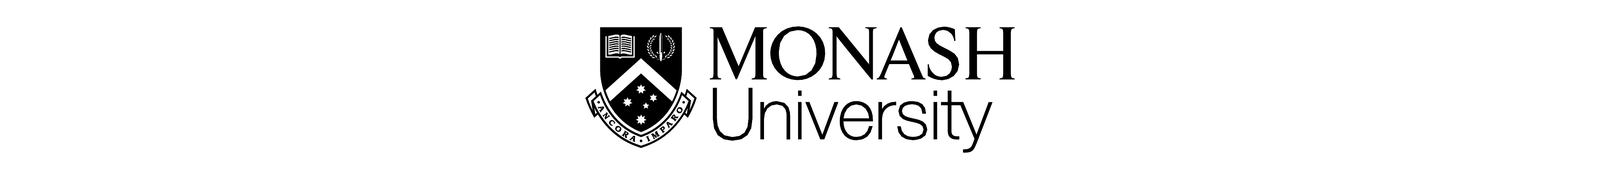

<div align="center">
  <h1>FIT5196 Data Wrangling</h1>
  <h2>Assessment 2: Data Cleansing, Audit and Transformation</h2>
  <h3>Group030 — Technical Solution Notebook</h3>
  <h4>Semester 2, 2026</h4>
</div>

| Group member | Full name | Student ID |
|---:|---|---|
| 1 | King Man Chan | 36550779 |
| 2 | Yinglin Fang | 34814248 |
| 3 | Sizhe Hong | 35381949 |
| 4 | Xinhang Ren | 35134410 |
| 5 | Guohou Zhang | 35800275 |

# Executive summary

We cleaned three separate Group030 order batches, each with a different data-quality problem. The missing and dirty outputs keep all 500 original orders. For the outlier batch, we removed 24 orders whose delivery charges were inconsistent with the seasonal delivery relationship, leaving 476 retained orders.

We inferred the current product prices from reliable shopping-cart equations and fitted a separate delivery-charge model for each season. Before using these models for cleaning, we tested them on held-out observations. We also recorded every imputation, correction and removal in a 184-row audit log, then read the saved files back and checked their schemas, IDs, business rules and agreement with the log.

For the final task, we combined the 1,476 retained orders into 471 customer profiles. We compared the original values with z-score standardisation, min-max scaling and nonlinear transformations to prepare the features for later distance-based exploration.

| Retained orders | Customer profiles | Audited actions | Validation checks |
|:---:|:---:|:---:|:---:|
| **1,476** | **471** | **184** | **50 / 50** |
| 500 missing + 500 dirty + 476 outlier | From cleaned outputs only | 80 imputations + 80 repairs + 24 removals | All executable checks passed |

# Contents

1. [Reproducibility and configuration](#0-reproducibility-and-configuration)  
2. [Initial investigation and evidence selection](#1-initial-investigation-and-evidence-selection)  
3. [Shared business rules and learned relationships](#2-shared-business-rules-and-learned-relationships)  
4. [Missing-data recovery](#3-missing-data-recovery)  
5. [Dirty-data diagnosis and repair](#4-dirty-data-diagnosis-and-repair)  
6. [Delivery-charge outlier removal](#5-delivery-charge-outlier-removal)  
7. [Audit trail and final validation](#6-audit-trail-and-final-validation)  
8. [Customer profiling and transformation](#7-customer-profiling-and-transformation)

# 0. Reproducibility and configuration

We begin by keeping the group ID and all file paths in one place. This lets us run the notebook from either the repository root or the `notebooks/` folder. The workflow reads the raw files and writes all generated files to `outputs/`.

We first locate the project folder from the submitted `src` directory and add it to Python's import path. This keeps code discovery independent of where the marker places the supplied input data.

In [1]:
# Purpose: identify the group and resolve the repository root.
from pathlib import Path
import sys

GROUP_ID = "Group030"
WORKING_DIR = Path.cwd().resolve()
PROJECT_CANDIDATES = [WORKING_DIR, WORKING_DIR.parent]
PROJECT_ROOT = next(
    (candidate for candidate in PROJECT_CANDIDATES if (candidate / "src").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    checked = ", ".join(str(path / "src") for path in PROJECT_CANDIDATES)
    raise FileNotFoundError(f"Could not locate the submitted src directory. Checked: {checked}")

# Local helper modules live under PROJECT_ROOT/src.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root resolved:", PROJECT_ROOT.name)

Project root resolved: FIT5196-A2


Next, we define the input and output locations used throughout the notebook. The input folder is detected in the repository layout, beside the notebook, or beside the submission folder. If a marker uses another location, only `DATA_DIR` in this cell needs to be changed.

In [2]:
# Purpose: define every input and output path used later in the workflow.
DATA_DIR_CANDIDATES = [
    PROJECT_ROOT / "data" / "raw" / f"{GROUP_ID}_A2",
    PROJECT_ROOT / f"{GROUP_ID}_A2",
    PROJECT_ROOT.parent / f"{GROUP_ID}_A2",
]
DATA_DIR = next((path for path in DATA_DIR_CANDIDATES if path.is_dir()), None)
if DATA_DIR is None:
    checked = ", ".join(str(path) for path in DATA_DIR_CANDIDATES)
    raise FileNotFoundError(
        f"Could not locate the supplied {GROUP_ID} input folder. "
        f"Set DATA_DIR in this cell. Checked: {checked}"
    )
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DIRTY_INPUT = DATA_DIR / f"{GROUP_ID}_dirty_data.csv"
MISSING_INPUT = DATA_DIR / f"{GROUP_ID}_missing_data.csv"
OUTLIER_INPUT = DATA_DIR / f"{GROUP_ID}_outlier_data.csv"
WAREHOUSES_INPUT = DATA_DIR / "warehouses.csv"
RESOURCE_CONTRACT = DATA_DIR / "resource_contract.json"
NLTK_DATA_DIR = DATA_DIR / "resources" / "nltk_data"
MANIFEST_INPUT = DATA_DIR / "A2_manifest.json"

DIRTY_OUTPUT = OUTPUT_DIR / f"{GROUP_ID}_dirty_clean.csv"
MISSING_OUTPUT = OUTPUT_DIR / f"{GROUP_ID}_missing_clean.csv"
OUTLIER_OUTPUT = OUTPUT_DIR / f"{GROUP_ID}_outlier_clean.csv"
AUDIT_OUTPUT = OUTPUT_DIR / "audit_log.csv"

print("Input directory configured:", DATA_DIR)
print("Output directory configured:", OUTPUT_DIR)

Input directory configured: /home/user/FIT5196-A2/data/raw/Group030_A2
Output directory configured: /home/user/FIT5196-A2/outputs


Keeping the paths together makes the workflow easier to rerun and review. It also separates environment setup from the rules used to diagnose and repair the data.

## 0.1 Environment and dependencies

We use pandas and NumPy for data handling, scikit-learn for the linear models, Matplotlib for the figures and NLTK 3.9.2 for VADER sentiment scoring. Every train/test split uses the same random seed so that the reported results can be reproduced.

We import the standard Python libraries first. Keeping these imports separate from our own modules makes it easier to see which parts come from external packages.

In [3]:
# Purpose: import standard analysis, modelling and display dependencies.
import hashlib
import json
import platform

import matplotlib
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

We then import the cleaning functions written for this assignment. These modules contain the rules for the missing, dirty and outlier batches and are submitted with the notebook.

In [4]:
# Purpose: import the reproducible cleaning pipelines submitted with the notebook.
from src.dirty_cleaning import clean_dirty_batch
from src.missing_cleaning import (
    MODEL_FEATURES,
    ORDER_COLUMNS,
    SEASON_BY_MONTH,
    calculate_order_price,
    clean_missing_batch,
    fit_seasonal_models,
    infer_product_prices,
    nearest_warehouse,
    parse_cart,
    parse_order_date,
    setup_vader,
)
from src.outlier_cleaning import clean_outlier_batch

Here we set the random seed for reproducible held-out splits and define the colours used throughout the figures.

In [5]:
# Purpose: fix the only random operation and define one colour system.
RANDOM_STATE = 5196
MONASH_BLUE = "#006DAE"
NAVY = "#17324D"
TEAL = "#00A6A6"
CORAL = "#C44E52"
GOLD = "#E3A008"
SLATE = "#64748B"
BATCH_COLOURS = {"dirty": CORAL, "missing": MONASH_BLUE, "outlier": TEAL}

We use one set of Matplotlib defaults so the figures have consistent fonts, grid lines and sizes.

In [6]:
# Purpose: keep figure appearance consistent across the report.
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 180,
    "figure.facecolor": "white",
    "axes.facecolor": "#F8FAFC",
    "axes.edgecolor": "#CBD5E1",
    "axes.titlecolor": NAVY,
    "axes.titleweight": "bold",
    "axes.labelcolor": NAVY,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.22,
    "legend.frameon": False,
    "font.size": 10,
})

We also adjust two pandas display settings so that wide validation tables are easier to read.

In [7]:
# Purpose: configure readable displays for wide tables.
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)

In [8]:
# Purpose: report exact software versions used by the executed notebook.
environment = pd.DataFrame(
    {
        "component": ["Python", "pandas", "NumPy", "scikit-learn", "Matplotlib", "NLTK"],
        "version": [
            platform.python_version(),
            pd.__version__,
            np.__version__,
            sklearn.__version__,
            matplotlib.__version__,
            nltk.__version__,
        ],
    }
)
display(environment)

,component,version
0,Python,3.12.3
1,pandas,3.0.5
2,NumPy,2.5.1
3,scikit-learn,1.9.0
4,Matplotlib,3.11.1
5,NLTK,3.9.2


We report the versions used for this run and also list the required versions in `requirements.txt`. This makes it easier to reproduce the notebook in a fresh environment.

## 0.2 Input integrity and frozen resource checks

Before reading the data, we compare each supplied file with the SHA-256 value in the Group030 manifest. We also verify the local VADER lexicon and the required NLTK version. This check tells us that the analysis starts from the original allocated files.

In [9]:
# Purpose: verify every allocated input against the supplied SHA-256 manifest.
manifest = json.loads(MANIFEST_INPUT.read_text(encoding="utf-8"))
manifest_checks = []

for entry in manifest["files"]:
    path = DATA_DIR / entry["path"]
    actual_hash = hashlib.sha256(path.read_bytes()).hexdigest()
    manifest_checks.append(
        {
            "path": entry["path"],
            "exists": path.exists(),
            "expected_sha256": entry["sha256"],
            "actual_sha256": actual_hash,
            "passed": actual_hash == entry["sha256"],
        }
    )

manifest_check_table = pd.DataFrame(manifest_checks)
display(manifest_check_table[["path", "exists", "passed"]])
assert manifest_check_table["passed"].all()

,path,exists,passed
0,Group030_dirty_data.csv,True,True
1,Group030_missing_data.csv,True,True
2,Group030_outlier_data.csv,True,True
3,README.md,True,True
4,input_manifest.csv,True,True
5,resource_contract.json,True,True
6,resources/nltk_data/sentiment/vader_lexicon.zip,True,True
7,warehouses.csv,True,True


In [10]:
# Purpose: verify the frozen VADER resource contract before sentiment analysis.
resource_contract = json.loads(RESOURCE_CONTRACT.read_text(encoding="utf-8"))
lexicon_path = DATA_DIR / resource_contract["vader_lexicon_relative_path"]
lexicon_hash = hashlib.sha256(lexicon_path.read_bytes()).hexdigest()

resource_check = pd.DataFrame(
    {
        "check": ["Required NLTK version", "Frozen lexicon SHA-256"],
        "expected": [resource_contract["nltk_version"], resource_contract["vader_lexicon_sha256"]],
        "observed": [nltk.__version__, lexicon_hash],
    }
)
resource_check["passed"] = resource_check["expected"] == resource_check["observed"]
display(resource_check)
assert resource_check["passed"].all()

,check,expected,observed,passed
0,Required NLTK version,3.9.2,3.9.2,True
1,Frozen lexicon SHA-256,8adba4294eef3964d820bf655e37e61bdc3a341994356af59b74fb3b4a36ce5c,8adba4294eef3964d820bf655e37e61bdc3a341994356af59b74fb3b4a36ce5c,True


All file and VADER checks pass, confirming that the supplied Group030 data and frozen local sentiment resource are available.

# 1. Initial investigation and evidence selection

The three CSV files have the same 16 columns but contain different orders. We keep them separate while cleaning because each batch has a different type of problem, then combine the cleaned outputs when building the customer profiles for Task 3.

We load the three order files and the warehouse reference file with pandas. `order_id` and `customer_id` are read as strings so that their formatting is preserved.

In [11]:
# Purpose: load the three order batches and warehouse reference table.
read_options = {"dtype": {"order_id": "string", "customer_id": "string"}}
dirty_raw = pd.read_csv(DIRTY_INPUT, **read_options)
missing_raw = pd.read_csv(MISSING_INPUT, **read_options)
outlier_raw = pd.read_csv(OUTLIER_INPUT, **read_options)
warehouses = pd.read_csv(WAREHOUSES_INPUT)

# Source identity remains attached through this named mapping.
raw_batches = {
    "dirty": dirty_raw,
    "missing": missing_raw,
    "outlier": outlier_raw,
}

We start with a compact overview of each batch: its row and column counts, the number of customers, whether order IDs are unique and how many values are missing. This gives us a baseline before any changes are made.

In [12]:
# Purpose: summarise each untouched input batch at order level.
batch_overview = pd.DataFrame([
    {
        "batch": name,
        "rows": len(frame),
        "columns": frame.shape[1],
        "unique_orders": frame["order_id"].nunique(),
        "customers": frame["customer_id"].nunique(),
        "missing_cells": int(frame.isna().sum().sum()),
    }
    for name, frame in raw_batches.items()
])
display(batch_overview)

,batch,rows,columns,unique_orders,customers,missing_cells
0,dirty,500,16,500,321,0
1,missing,500,16,500,323,80
2,outlier,500,16,500,318,0


Each batch contains 500 rows and the expected 16 columns. Order IDs are unique within every file, and only the missing batch contains empty fields. The customer count is lower than the order count because some customers placed more than one order.

## 1.1 Schema, types and key integrity

We check the schema and order IDs before carrying out any calculations. If a file has the wrong columns or duplicate IDs, later repairs cannot be matched reliably to the original orders.

In [13]:
# Purpose: compare schemas, dtypes and key integrity across the three raw batches.
schema_check = pd.DataFrame(
    {
        name: pd.Series(frame.dtypes.astype(str), index=frame.columns)
        for name, frame in raw_batches.items()
    }
)
display(schema_check)

assert all(list(frame.columns) == ORDER_COLUMNS for frame in raw_batches.values())
assert all(frame["order_id"].is_unique for frame in raw_batches.values())

combined_raw_ids = pd.concat(
    [frame[["order_id"]].assign(source_batch=name) for name, frame in raw_batches.items()],
    ignore_index=True,
)
print("Distinct IDs across all raw batches:", combined_raw_ids["order_id"].nunique())
assert combined_raw_ids["order_id"].is_unique

,dirty,missing,outlier
order_id,string,string,string
customer_id,string,string,string
date,str,str,str
nearest_warehouse,str,str,str
shopping_cart,str,str,str
order_price,float64,float64,float64
delivery_charges,float64,float64,float64
customer_lat,float64,float64,float64
customer_long,float64,float64,float64
coupon_discount,int64,int64,int64


Distinct IDs across all raw batches: 1500


Across the three inputs, all 1,500 order IDs are distinct, confirming that the files contain three separate order batches.

## 1.2 Missingness diagnosis

We count missing values by field and also check how many fields are missing in each affected row. Because the counts are uniform and the row-level result has only one category, compact tables communicate the evidence clearly. The exact text `No review submitted` remains a valid sentinel under the supplied rule.

In [14]:
# Purpose: summarise missingness by field and by affected row.
missingness = pd.DataFrame(
    {name: frame.isna().sum() for name, frame in raw_batches.items()}
)
missingness.index.name = "field"
affected_missingness = missingness.loc[missingness.sum(axis=1) > 0]

missing_field_summary = (
    affected_missingness[["missing"]]
    .rename(columns={"missing": "missing_values"})
    .reset_index()
)
missing_field_summary["missing_rate_percent"] = (
    100 * missing_field_summary["missing_values"] / len(missing_raw)
).round(1)

missing_per_row = missing_raw.isna().sum(axis=1)
affected_rows = missing_per_row.loc[missing_per_row > 0]
row_missingness_summary = pd.DataFrame(
    {
        "measure": [
            "Total missing cells",
            "Rows containing a missing value",
            "Maximum missing fields in an affected row",
            "Affected rows with more than one missing field",
        ],
        "observed_value": [
            int(missing_raw.isna().sum().sum()),
            int(len(affected_rows)),
            int(affected_rows.max()),
            int((affected_rows > 1).sum()),
        ],
    }
)

display(missing_field_summary)
display(row_missingness_summary)

,field,missing_values,missing_rate_percent
0,nearest_warehouse,10,2.0
1,order_price,10,2.0
2,delivery_charges,10,2.0
3,order_total,10,2.0
4,season,10,2.0
5,is_expedited_delivery,10,2.0
6,distance_to_nearest_warehouse,10,2.0
7,is_happy_customer,10,2.0


,measure,observed_value
0,Total missing cells,80
1,Rows containing a missing value,80
2,Maximum missing fields in an affected row,1
3,Affected rows with more than one missing field,0


The tables show 80 missing cells in 80 different rows. Each of the eight affected fields has ten missing values, equal to 2.0% of the 500-row batch, and no row is missing more than one field. Because the remaining values in this batch are guaranteed to be correct, they can be used to recover the omitted value.

## 1.3 Categorical values and numeric distributions

We inspect category labels, Boolean counts and numeric ranges to find values that do not fit the published rules. The percentage discount is plotted separately because it takes a small set of discrete values.

In [15]:
# Purpose: compare observed categorical values with the allowed labels and encodings.
categorical_summary = []
for batch_name, frame in raw_batches.items():
    for column in ["nearest_warehouse", "season", "is_expedited_delivery", "is_happy_customer"]:
        categorical_summary.append(
            {
                "batch": batch_name,
                "field": column,
                "value_counts": frame[column].value_counts(dropna=False).to_dict(),
            }
        )
display(pd.DataFrame(categorical_summary))

,batch,field,value_counts
0,dirty,nearest_warehouse,"{'Thompson': 218, 'Bakers': 213, 'Nickolson': 61, 'THOMPSON WH': 3, 'Baker's': 3, 'Nickolsen': 2}"
1,dirty,season,"{'Autumn': 142, 'Winter': 123, 'Summer': 121, 'Spring': 114}"
2,dirty,is_expedited_delivery,"{False: 408, True: 92}"
3,dirty,is_happy_customer,"{True: 423, False: 77}"
4,missing,nearest_warehouse,"{'Bakers': 222, 'Thompson': 191, 'Nickolson': 77, nan: 10}"
5,missing,season,"{'Summer': 133, 'Winter': 125, 'Spring': 121, 'Autumn': 111, nan: 10}"
6,missing,is_expedited_delivery,"{False: 396, True: 94, nan: 10}"
7,missing,is_happy_customer,"{True: 406, False: 84, nan: 10}"
8,outlier,nearest_warehouse,"{'Bakers': 221, 'Thompson': 214, 'Nickolson': 65}"
9,outlier,season,"{'Autumn': 135, 'Summer': 133, 'Winter': 119, 'Spring': 113}"


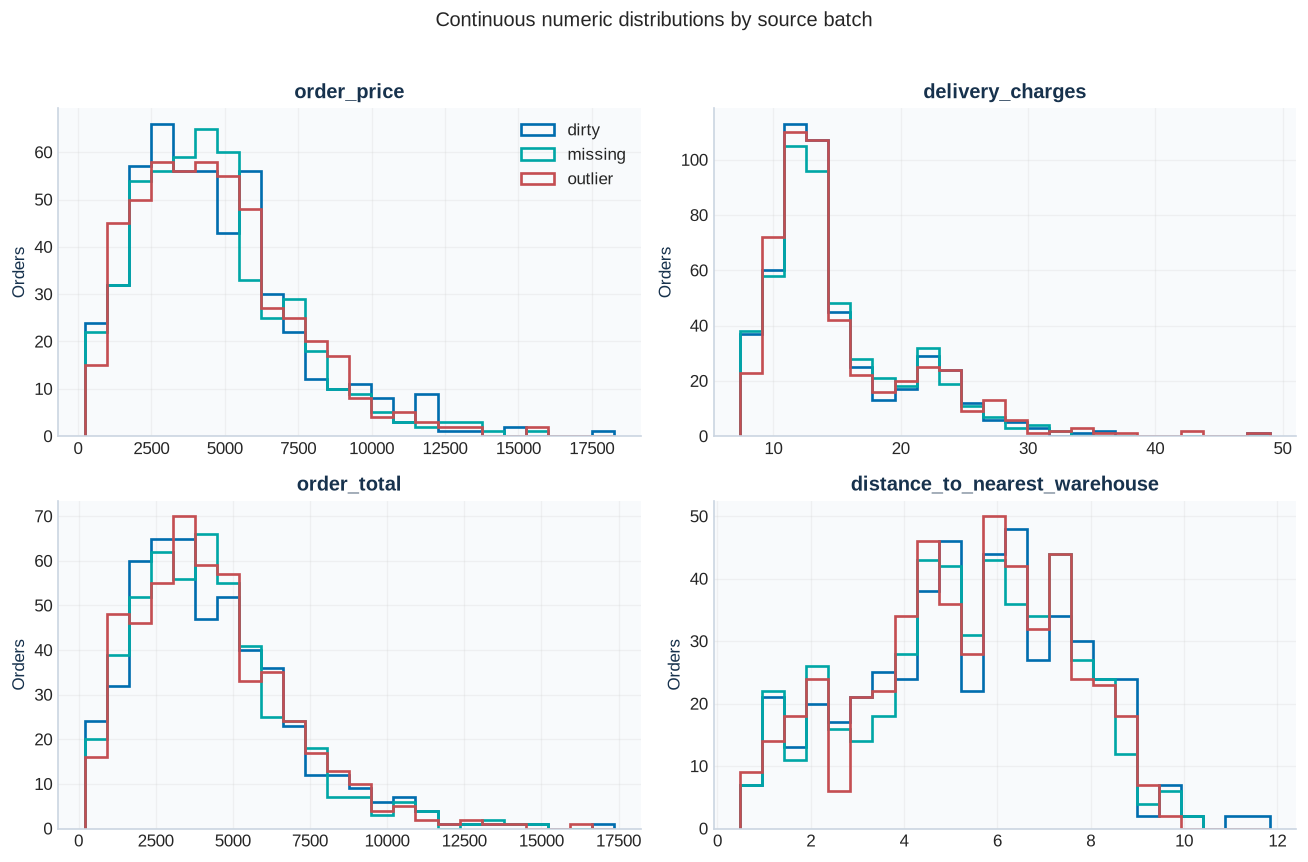

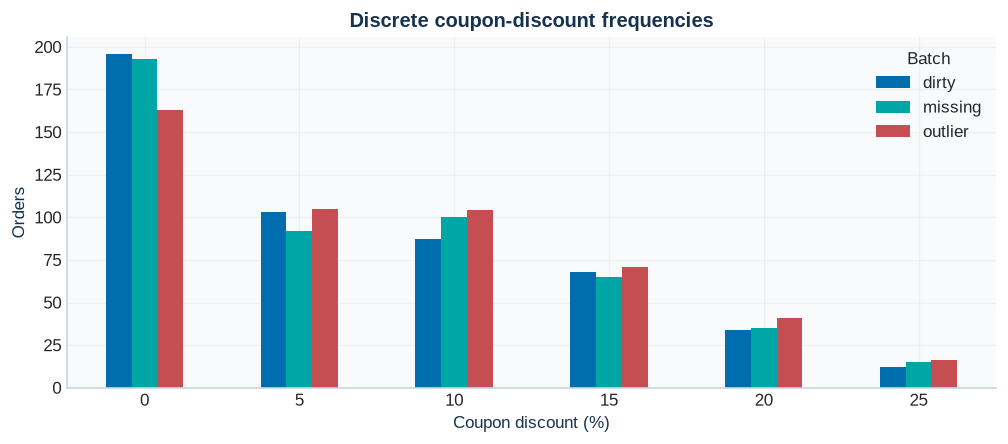

In [16]:
# Purpose: compare continuous distributions and the discrete discount separately.
continuous_numeric = [
    "order_price", "delivery_charges", "order_total",
    "distance_to_nearest_warehouse",
]
batch_colours = {"dirty": MONASH_BLUE, "missing": TEAL, "outlier": CORAL}

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for axis, column in zip(axes.flatten(), continuous_numeric):
    pooled = pd.concat([frame[column].dropna() for frame in raw_batches.values()])
    bins = np.histogram_bin_edges(pooled, bins=24)
    for batch_name, frame in raw_batches.items():
        axis.hist(frame[column].dropna(), bins=bins, histtype="step", linewidth=1.6,
                  color=batch_colours[batch_name], label=batch_name)
    axis.set(title=column, ylabel="Orders")
axes[0, 0].legend(frameon=False)
fig.suptitle("Continuous numeric distributions by source batch", y=1.02)
plt.tight_layout()
plt.show()

discount_counts = pd.concat(
    {name: frame["coupon_discount"].value_counts().sort_index() for name, frame in raw_batches.items()},
    axis=1,
).fillna(0)
ax = discount_counts.plot(kind="bar", figsize=(8.5, 3.8), color=list(batch_colours.values()))
ax.set(xlabel="Coupon discount (%)", ylabel="Orders", title="Discrete coupon-discount frequencies")
ax.legend(title="Batch", frameon=False)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The monetary variables cover wide ranges, while coupon discounts occur at a few fixed percentage levels. Delivery charges overlap heavily across the three batches. This means that a high charge is not automatically an outlier: distance, season, expedited delivery and customer happiness must be considered together.

## 1.4 Coordinate plausibility and spatial distribution

Melbourne lies in the Southern Hemisphere, so customer latitudes should be negative and should fall near the supplied warehouses. We first check the raw dirty-batch coordinates against a broad Melbourne window, then use a longitude–latitude scatter plot to inspect the plausible coordinates.

We classify each dirty-batch coordinate before making any repair. A plausible record must have latitude between −38.2° and −37.3° and longitude between 144.4° and 145.7°. We separately count positive latitudes whose absolute magnitudes still fall inside the Melbourne latitude band, because that pattern is specific evidence of a missing minus sign.

In [17]:
# Purpose: distinguish plausible Melbourne coordinates from latitude-sign errors.
plausible_dirty_mask = (
    dirty_raw["customer_lat"].between(-38.2, -37.3)
    & dirty_raw["customer_long"].between(144.4, 145.7)
)
latitude_sign_issue_mask = (
    dirty_raw["customer_lat"].gt(0)
    & dirty_raw["customer_lat"].abs().between(37.3, 38.2)
    & dirty_raw["customer_long"].between(144.4, 145.7)
)
other_coordinate_issue_mask = ~(plausible_dirty_mask | latitude_sign_issue_mask)
location_issues = dirty_raw.loc[~plausible_dirty_mask]

coordinate_check = pd.DataFrame(
    {
        "classification": [
            "Plausible Melbourne coordinate",
            "Positive latitude with Melbourne magnitude",
            "Other coordinate issue",
        ],
        "orders": [
            int(plausible_dirty_mask.sum()),
            int(latitude_sign_issue_mask.sum()),
            int(other_coordinate_issue_mask.sum()),
        ],
        "interpretation": [
            "Raw coordinate is inside the broad Melbourne window",
            "Latitude is in the Northern Hemisphere; likely missing minus sign",
            "Would require a different diagnosis",
        ],
    }
)
display(coordinate_check)

,classification,orders,interpretation
0,Plausible Melbourne coordinate,492,Raw coordinate is inside the broad Melbourne window
1,Positive latitude with Melbourne magnitude,8,Latitude is in the Northern Hemisphere; likely missing minus sign
2,Other coordinate issue,0,Would require a different diagnosis


Because valid latitudes lie near −38° and the suspect values near +38°, a single axis would compress the valid points into a line. The two panels give the plausible and inconsistent latitude bands their own axes, making the sign problem easier to see.

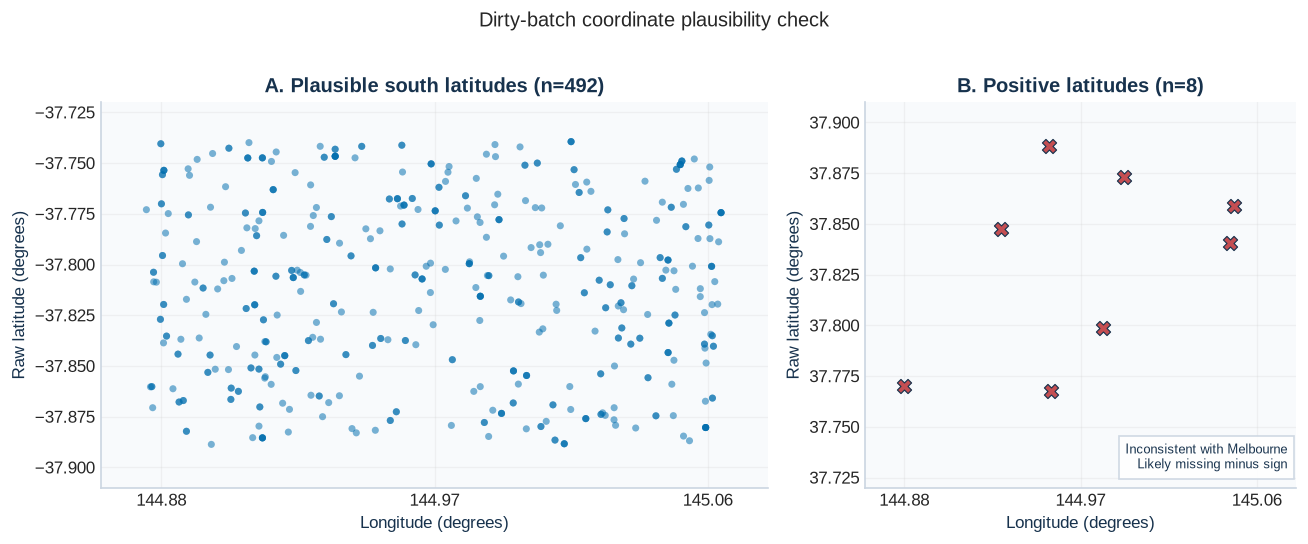

In [18]:
# Purpose: show the plausible and positive latitude bands in separate panels.
plausible_dirty = dirty_raw.loc[plausible_dirty_mask]
sign_issue_rows = dirty_raw.loc[latitude_sign_issue_mask]

fig, axes = plt.subplots(
    1, 2, figsize=(11, 4.4), sharex=True,
    gridspec_kw={"width_ratios": [1.55, 1]},
)

axes[0].scatter(
    plausible_dirty["customer_long"], plausible_dirty["customer_lat"],
    s=18, alpha=0.52, color=MONASH_BLUE, edgecolors="none",
)
axes[0].set(
    title=f"A. Plausible south latitudes (n={len(plausible_dirty)})",
    xlabel="Longitude (degrees)", ylabel="Raw latitude (degrees)",
    ylim=(-37.91, -37.72),
)

axes[1].scatter(
    sign_issue_rows["customer_long"], sign_issue_rows["customer_lat"],
    marker="X", s=72, color=CORAL, edgecolor=NAVY, linewidth=0.7,
)
axes[1].set(
    title=f"B. Positive latitudes (n={len(sign_issue_rows)})",
    xlabel="Longitude (degrees)", ylabel="Raw latitude (degrees)",
    ylim=(37.72, 37.91),
)
axes[1].text(
    0.98, 0.04, "Inconsistent with Melbourne\nLikely missing minus sign",
    transform=axes[1].transAxes, ha="right", va="bottom", fontsize=8,
    color=NAVY, bbox={"facecolor": "white", "edgecolor": "#CBD5E1", "alpha": 0.9},
)

for axis in axes:
    axis.set_xlim(144.86, 145.08)
    axis.set_xticks([144.88, 144.97, 145.06])

fig.suptitle("Dirty-batch coordinate plausibility check", y=1.02)
plt.tight_layout()
plt.show()

We next inspect the plausible coordinates from all three batches together with the supplied warehouses. The plot uses the original longitude and latitude values, with the aspect ratio adjusted for Melbourne's latitude.

In [19]:
# Purpose: build display-only masks and bounds for the Melbourne detail.
plausible_locations = {
    batch_name: (
        frame["customer_lat"].between(-38.2, -37.3)
        & frame["customer_long"].between(144.4, 145.7)
    )
    for batch_name, frame in raw_batches.items()
}
plausible_points = pd.concat([
    frame.loc[plausible_locations[name], ["customer_long", "customer_lat"]]
    for name, frame in raw_batches.items()
])
longitude_limits = (
    plausible_points["customer_long"].min() - 0.025,
    plausible_points["customer_long"].max() + 0.025,
)
latitude_limits = (
    plausible_points["customer_lat"].min() - 0.025,
    plausible_points["customer_lat"].max() + 0.025,
)

In [20]:
# Purpose: label the supplied warehouse markers clearly.
def annotate_warehouse_labels(axis):
    offsets = {
        "Bakers": (10, 9),
        "Thompson": (-66, 13),
        "Nickolson": (10, -18),
    }
    for warehouse in warehouses.itertuples(index=False):
        axis.annotate(
            warehouse.warehouse,
            (warehouse.longitude, warehouse.latitude),
            xytext=offsets[warehouse.warehouse],
            textcoords="offset points",
            fontsize=8,
            color=NAVY,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.78, "pad": 1.5},
        )

Colour identifies the source batch and marker shape provides a second visual cue. The labelled stars show the warehouse locations and help confirm that the three batches share the same compact Melbourne coordinate range.

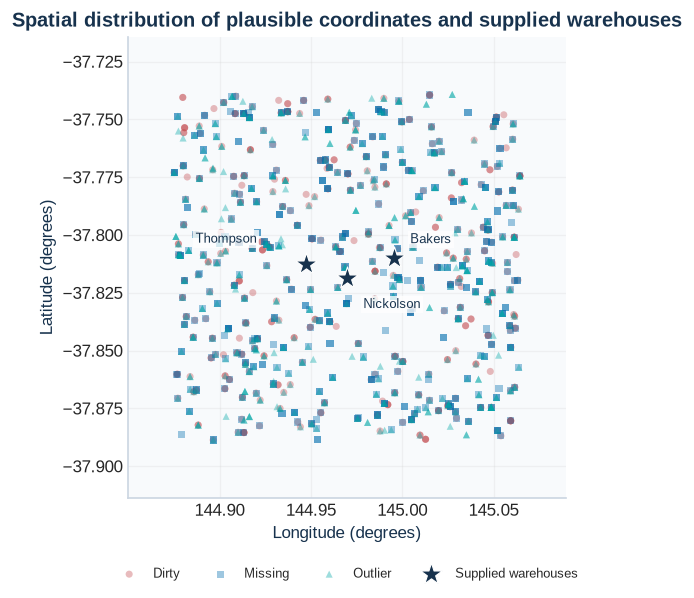

In [21]:
# Purpose: inspect the spatial distribution of plausible coordinates and warehouses.
batch_markers = {"dirty": "o", "missing": "s", "outlier": "^"}
fig, ax = plt.subplots(figsize=(9, 5.6))

for batch_name, frame in raw_batches.items():
    plausible = plausible_locations[batch_name]
    ax.scatter(
        frame.loc[plausible, "customer_long"],
        frame.loc[plausible, "customer_lat"],
        s=18,
        alpha=0.38,
        marker=batch_markers[batch_name],
        color=BATCH_COLOURS[batch_name],
        edgecolors="none",
        label=batch_name.title(),
        rasterized=True,
    )

ax.scatter(
    warehouses["longitude"], warehouses["latitude"],
    marker="*", s=190, color=NAVY, edgecolor="white", linewidth=0.7,
    label="Supplied warehouses", zorder=5,
)
annotate_warehouse_labels(ax)

ax.set_aspect(1 / np.cos(np.radians(-37.8)), adjustable="box")
ax.set(
    xlim=longitude_limits,
    ylim=latitude_limits,
    xlabel="Longitude (degrees)",
    ylabel="Latitude (degrees)",
    title="Spatial distribution of plausible coordinates and supplied warehouses",
)
ax.legend(
    fontsize=8, ncol=4, loc="upper center",
    bbox_to_anchor=(0.5, -0.14), borderaxespad=0,
)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

The plausibility check finds 492 dirty-batch coordinates inside the broad Melbourne window and eight positive latitudes. All eight positive values have absolute magnitudes between 37.3° and 38.2°, and their longitudes remain within the Melbourne range. Together with the batch guarantee that a dirty row has at most one incorrect field, this is strong evidence that the latitude sign is the corrupted information. The second figure shows that the remaining coordinates from all batches occupy a compact range around the three supplied warehouses.

## 1.5 Evidence-selection policy

| Evidence source | Appropriate use | Exclusion or safeguard |
|---|---|---|
| Observed missing-batch values | Product prices and delivery-model fitting | Exclude rows missing the response or any required predictor |
| Dirty batch | Rule-based repair after independent diagnosis | Do not use unresolved fields to train a model |
| Outlier batch | Residual-based target for anomaly decisions | Do not train the delivery model on potentially anomalous charges |
| `warehouses.csv` | Warehouse names and coordinates | Treated as the supplied correct reference |
| Frozen VADER resource | Happiness reconstruction and checks | Verify NLTK version and SHA-256; no downloads or text rewriting |

This policy keeps unreliable values out of model training and prevents a repair from being justified by the value it replaces.

# 2. Shared business rules and learned relationships

The cleaning functions are stored in the submitted Python modules, but we show the important inputs, equations and checks here so the reasoning can be followed directly from the notebook.

## 2.1 Shopping-cart parsing and product inventory

We parse every cart with `json.loads` and check that each item has a product name and a positive integer quantity. We infer the product list and current prices from the supplied A2 carts.

In [22]:
# Purpose: parse JSON carts and establish the current product inventory.
parsed_carts = missing_raw["shopping_cart"].map(parse_cart)
products = sorted(
    {
        item["product"]
        for cart in parsed_carts
        for item in cart
    }
)
cart_structure_summary = pd.DataFrame(
    {
        "metric": ["valid carts", "distinct products", "minimum cart lines", "maximum cart lines"],
        "value": [len(parsed_carts), len(products), parsed_carts.map(len).min(), parsed_carts.map(len).max()],
    }
)
display(cart_structure_summary)
display(pd.DataFrame({"product": products}))

,metric,value
0,valid carts,500
1,distinct products,12
2,minimum cart lines,1
3,maximum cart lines,5


,product
0,Candle Arc 420
1,Candle Bloom 316
2,Candle Bloom 838
3,Candle Edge 572
4,Candle Lumen 778
5,Candle Shift 232
6,Vela Atlas 863
7,Vela Echo 547
8,Vela Echo 583
9,Vela Halo 137


The valid carts contain 12 products and between one and five distinct line items. Product names and quantities are complete in the source data, so we keep them unchanged.

## 2.2 Current-price inference

We infer the current product prices from orders whose cart and `order_price` can be used reliably. For order \(j\), the relationship is

\[
y_j = \sum_{i=1}^{12} q_{ji}p_i,
\]

where \(q_{ji}\) is the quantity of product \(i\), \(p_i\) is its unit price and \(y_j\) is the observed order price. Combining many orders gives the system \(Qp=y\). The quantity matrix must have rank 12 for all 12 prices to be identified.

In [23]:
# Purpose: infer unit prices and display rank and held-out reconstruction diagnostics.
price_map, price_diagnostics = infer_product_prices(missing_raw)
price_table = pd.DataFrame(
    [{"product": product, "unit_price_AUD": value} for product, value in price_map.items()]
)

display(price_diagnostics)
display(price_table)

,observed_equations,training_equations,heldout_equations,training_rank,product_count,heldout_max_absolute_error,all_equations_max_absolute_error
0,490,392,98,12,12,0.0,0.0


,product,unit_price_AUD
0,Candle Arc 420,2742.91
1,Candle Bloom 316,698.58
2,Candle Bloom 838,1098.41
3,Candle Edge 572,1340.90
4,Candle Lumen 778,1371.48
5,Candle Shift 232,801.49
6,Vela Atlas 863,3657.74
7,Vela Echo 547,899.34
8,Vela Echo 583,1072.62
9,Vela Halo 137,769.91


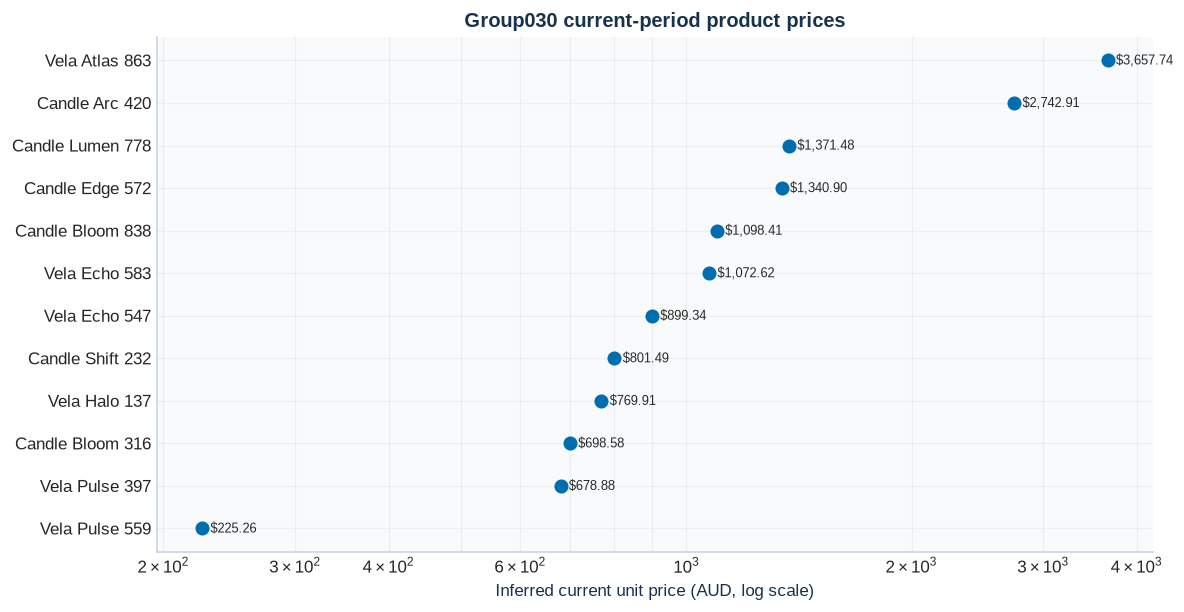

In [24]:
# Purpose: display inferred product prices across their full range.
ordered_prices = price_table.sort_values("unit_price_AUD")
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.scatter(ordered_prices["unit_price_AUD"], ordered_prices["product"],
           color=MONASH_BLUE, s=55, zorder=3)
for row in ordered_prices.itertuples(index=False):
    ax.annotate(f"${row.unit_price_AUD:,.2f}", (row.unit_price_AUD, row.product),
                xytext=(5, 0), textcoords="offset points", va="center", fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("Inferred current unit price (AUD, log scale)")
ax.set_title("Group030 current-period product prices")
ax.grid(axis="x", which="both", alpha=0.25)
plt.tight_layout()
plt.show()

The 392 equations used for estimation have rank 12, so the price vector is identifiable. After applying the required item-level rounding, the maximum absolute error is AUD 0.00 for all 98 held-out equations and all 490 observed equations. We therefore use these prices when an `order_price` is missing or demonstrably dirty. The price figure uses a logarithmic display axis because all prices are positive and differ by more than a factor of ten; the labels still show the exact AUD values used in the calculations.

## 2.3 Dates, geography and sentiment

We interpret year-first dates in year-first order and slash-formatted dates as day/month/year. Seasons are assigned from the Australian calendar. Distances are calculated with the Haversine formula using an Earth radius of 6,371 km and are rounded to four decimal places when reconstructed.

In [25]:
# Purpose: demonstrate deterministic date, warehouse and distance rules on a real row.
example_date = "01/03/2019"
parsed_example = parse_order_date(example_date)
example_warehouse, example_distance = nearest_warehouse(
    missing_raw.loc[0, "customer_lat"],
    missing_raw.loc[0, "customer_long"],
    warehouses,
)

rule_examples = pd.DataFrame(
    {
        "rule": ["day-first date", "derived season", "nearest warehouse", "Haversine distance (km)"],
        "example_result": [
            parsed_example.strftime("%Y-%m-%d"),
            SEASON_BY_MONTH[parsed_example.month],
            example_warehouse,
            round(example_distance, 4),
        ],
    }
)
display(rule_examples)

,rule,example_result
0,day-first date,2019-03-01
1,derived season,Autumn
2,nearest warehouse,Bakers
3,Haversine distance (km),7.1302


For the review field, we score the submitted English text exactly as it appears. Before scoring, we verify the frozen local lexicon and required NLTK version.

In [26]:
# Purpose: score submitted reviews with the supplied frozen VADER lexicon.
vader_analyzer = setup_vader(RESOURCE_CONTRACT, NLTK_DATA_DIR)
submitted_reviews = missing_raw.loc[
    missing_raw["latest_customer_review"] != "No review submitted",
    "latest_customer_review",
]
review_scores = submitted_reviews.map(
    lambda text: vader_analyzer.polarity_scores(text)["compound"]
)

sentiment_threshold = 0.05
sentiment_counts = pd.Series({
    "Below threshold": int((review_scores < sentiment_threshold).sum()),
    "Happy": int((review_scores >= sentiment_threshold).sum()),
})
display(sentiment_counts.to_frame("orders"))

,orders
Below threshold,89
Happy,411


VADER compound scores already lie between -1 and 1, so we plot them on that fixed range. The colours show which side of the published 0.05 happiness threshold each review falls on.

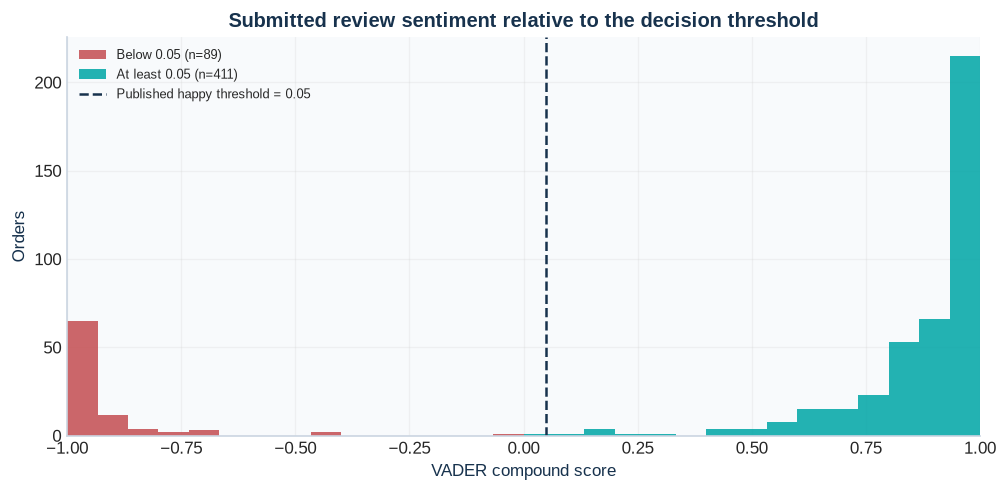

In [27]:
# Purpose: show VADER scores relative to the published decision threshold.
score_bins = np.linspace(-1, 1, 31)
unhappy_scores = review_scores.loc[review_scores < sentiment_threshold]
happy_scores = review_scores.loc[review_scores >= sentiment_threshold]

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.hist(
    [unhappy_scores, happy_scores], bins=score_bins, stacked=True,
    color=[CORAL, TEAL], alpha=0.86,
    label=[f"Below 0.05 (n={len(unhappy_scores)})", f"At least 0.05 (n={len(happy_scores)})"],
)
ax.axvline(
    sentiment_threshold, color=NAVY, linestyle="--", linewidth=1.5,
    label="Published happy threshold = 0.05",
)
ax.set(
    xlim=(-1, 1), xlabel="VADER compound score", ylabel="Orders",
    title="Submitted review sentiment relative to the decision threshold",
)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

A review is classified as happy when its VADER compound score is at least 0.05. This batch has no `No review submitted` sentinels; the cleaning function still maps that text to `True`.

## 2.4 Seasonal delivery-charge regression

We fit a separate ordinary least-squares model for each season:

\[
\widehat{delivery} = \beta_0 + \beta_1(distance) + \beta_2(expedited) + \beta_3(happy).
\]

The two Boolean predictors are encoded as 0 and 1. We leave the predictors in their original units because the model is being used to recover the stated business relationship, and the original units make the coefficients easier to interpret.

In [28]:
# Purpose: fit the four seasonal delivery-charge models used by the cleaning workflow.
seasonal_models, model_diagnostics = fit_seasonal_models(missing_raw)
model_display = model_diagnostics.copy()
for column in [
    "heldout_r_squared",
    "heldout_mae",
    "intercept",
    "distance_coefficient",
    "expedited_coefficient",
    "happy_coefficient",
]:
    model_display[column] = model_display[column].round(6)
display(model_display)

,season,reliable_observations,training_observations,heldout_observations,heldout_r_squared,heldout_mae,intercept,distance_coefficient,expedited_coefficient,happy_coefficient
0,Summer,125,100,25,1.000000,0.002419,9.999191,0.700247,9.999835,-2.000375
1,Autumn,103,82,21,1.000000,0.002164,9.996941,0.780000,11.000129,-2.996824
2,Winter,116,92,24,1.000000,0.002822,14.001254,0.849878,13.000287,-4.000432
3,Spring,106,84,22,0.999999,0.002197,9.999172,0.730389,10.499802,-2.500837


### Held-out evaluation

For each season, we use an 80/20 split with `random_state=5196`. The held-out rows provide an independent evaluation of the fitted model. After checking performance, we refit the operational model using all reliable observations for that season.

The training and evaluation samples contain rows with a known season, an observed delivery charge and complete predictor values.

In [29]:
# Purpose: exclude incomplete outcomes or predictors from model evaluation.
required_delivery_fields = ["season", "delivery_charges", *MODEL_FEATURES]
reliable_delivery = missing_raw.dropna(subset=required_delivery_fields)

# This count documents the evidence available in each seasonal subset.
display(
    reliable_delivery.groupby("season")
    .size()
    .rename("reliable_rows")
    .reindex(["Summer", "Autumn", "Winter", "Spring"])
    .to_frame()
)

,reliable_rows
season,
Summer,125
Autumn,103
Winter,116
Spring,106


We fit and test the four seasonal models separately. Predictions for the held-out rows are saved so that we can calculate the same diagnostics for every season.

In [30]:
# Purpose: evaluate one season-specific model on unseen rows.
heldout_rows = []
heldout_predictions = {}

for season in ["Summer", "Autumn", "Winter", "Spring"]:
    season_rows = reliable_delivery.loc[reliable_delivery["season"] == season]
    X = season_rows[MODEL_FEATURES].astype(float)
    y = season_rows["delivery_charges"].astype(float)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_STATE
    )
    evaluation_model = LinearRegression().fit(X_train, y_train)
    predictions = evaluation_model.predict(X_test)

    heldout_predictions[season] = (y_test, predictions)
    heldout_rows.append({
        "season": season,
        "training_n": len(X_train),
        "heldout_n": len(X_test),
        "heldout_R2": r2_score(y_test, predictions),
        "heldout_MAE_AUD": mean_absolute_error(y_test, predictions),
        "heldout_max_abs_residual": np.max(np.abs(y_test - predictions)),
    })

We report held-out \(R^2\), mean absolute error (MAE) and the largest absolute residual. \(R^2\) describes the explained variation, while MAE and the maximum error show the size of the prediction errors in Australian dollars.

In [31]:
# Purpose: present held-out metrics in a marker-readable table.
heldout_evaluation = pd.DataFrame(heldout_rows)
display(heldout_evaluation.round(6))

,season,training_n,heldout_n,heldout_R2,heldout_MAE_AUD,heldout_max_abs_residual
0,Summer,100,25,1.000000,0.002419,0.005385
1,Autumn,82,21,1.000000,0.002164,0.005942
2,Winter,92,24,1.000000,0.002822,0.005577
3,Spring,84,22,0.999999,0.002197,0.005915


Because predicted and observed charges are almost identical, a predicted-versus-observed plot would largely collapse onto the 45-degree line. We plot residuals instead, which makes the remaining error pattern easier to see. The dashed zero line represents a perfect prediction.

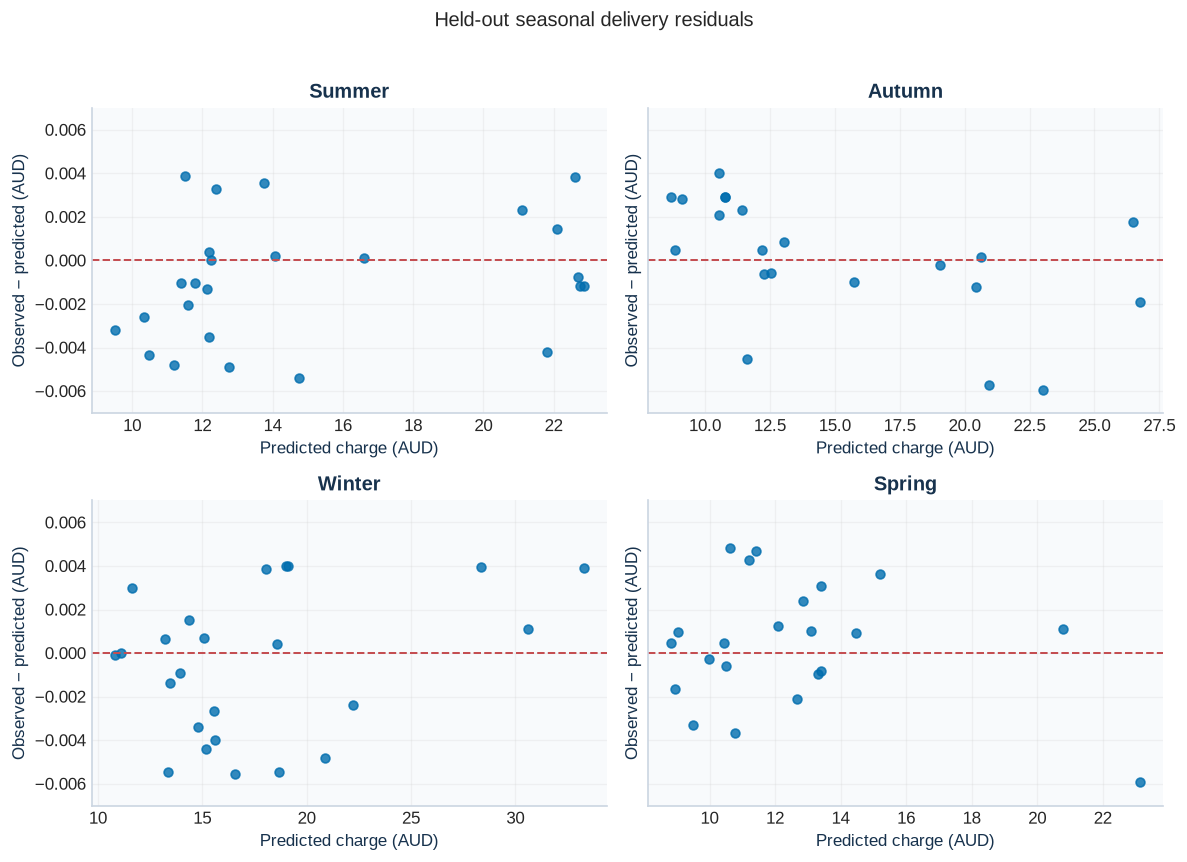

In [32]:
# Purpose: reveal held-out residual magnitude and structure by season.
all_heldout_residuals = np.concatenate([
    y_test.to_numpy() - predictions
    for y_test, predictions in heldout_predictions.values()
])
residual_limit = max(abs(all_heldout_residuals)) * 1.18
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharey=True)

for axis, season in zip(axes.flatten(), heldout_predictions):
    y_test, predictions = heldout_predictions[season]
    residual_values = y_test.to_numpy() - predictions
    axis.scatter(predictions, residual_values, alpha=0.8, color=MONASH_BLUE, s=28)
    axis.axhline(0, color=CORAL, linestyle="--", linewidth=1.2)
    axis.set(title=season, xlabel="Predicted charge (AUD)",
             ylabel="Observed − predicted (AUD)", ylim=(-residual_limit, residual_limit))

fig.suptitle("Held-out seasonal delivery residuals", y=1.02)
plt.tight_layout()
plt.show()

Every seasonal model achieves a held-out \(R^2\) of at least 0.999999, and every MAE is below AUD 0.003. The residuals stay close to zero with a similar spread across predicted values. This very strong fit is consistent with the fictional data being generated from a seasonal linear relationship. The preservation and residual checks in the following sections provide further evidence for the individual cleaning decisions.

# 3. Missing-data recovery

The missing batch contains omissions only, so every observed value stays unchanged. Exact relationships recover the rule-based fields, while the fitted seasonal model estimates missing delivery charges.

In [33]:
# Purpose: summarise missing fields and confirm the one-missing-value-per-row pattern.
missing_counts = missing_raw.isna().sum().loc[lambda values: values > 0]
missing_diagnosis = missing_counts.rename("missing_values").to_frame()
missing_diagnosis["affected_rows"] = [missing_raw[column].isna().sum() for column in missing_diagnosis.index]
display(missing_diagnosis)
print("Rows with at least one omission:", int(missing_raw.isna().any(axis=1).sum()))
print("Maximum omissions in one row:", int(missing_raw.isna().sum(axis=1).max()))

,missing_values,affected_rows
nearest_warehouse,10,10
order_price,10,10
delivery_charges,10,10
order_total,10,10
season,10,10
is_expedited_delivery,10,10
distance_to_nearest_warehouse,10,10
is_happy_customer,10,10


Rows with at least one omission: 80
Maximum omissions in one row: 1


| Missing field | Recovery evidence |
|---|---|
| `season` | Published month-to-season mapping |
| `nearest_warehouse` | Minimum Haversine distance across all warehouses |
| `distance_to_nearest_warehouse` | Haversine distance to the nearest warehouse |
| `order_price` | Parsed cart and independently inferred unit prices |
| `order_total` | Published discount-plus-delivery formula |
| `is_happy_customer` | Frozen VADER threshold and sentinel rule |
| `delivery_charges` | Applicable evaluated seasonal regression |
| `is_expedited_delivery` | Compare model residuals under 0 and 1 |

In [34]:
# Purpose: run the missing-value recovery pipeline and write its audited output.
missing_result = clean_missing_batch(
    missing_input=MISSING_INPUT,
    warehouses_input=WAREHOUSES_INPUT,
    resource_contract=RESOURCE_CONTRACT,
    nltk_data_dir=NLTK_DATA_DIR,
    missing_output=MISSING_OUTPUT,
    audit_output=AUDIT_OUTPUT,
)

display(missing_result.imputation_summary)

,field_name,confidence,imputed_values
0,delivery_charges,high,10
1,distance_to_nearest_warehouse,high,10
2,is_expedited_delivery,high,10
3,is_happy_customer,high,10
4,nearest_warehouse,high,10
5,order_price,high,10
6,order_total,high,10
7,season,high,10


Using these field-specific rules, we fill all 80 missing values while preserving every value that was originally present. Each of the eight affected fields contributes ten replacements.

## 3.1 Worked examples

The examples below are taken directly from the source data, cleaned output and audit log. They show how three different types of missing value were recovered.

In [35]:
# Purpose: trace selected missing-value repairs back to source and audit evidence.
missing_examples = missing_result.audit.loc[
    missing_result.audit["record_key"].isin(["CORD000601", "CORD000518", "CORD000578"]),
    ["record_key", "field_name", "original_value", "corrected_value", "method", "evidence"],
]
display(missing_examples)

example_price = (
    price_map["Vela Echo 583"]
    + price_map["Candle Bloom 316"]
    + price_map["Vela Echo 547"]
    + price_map["Vela Pulse 559"]
)
example_calculations = pd.DataFrame(
    {
        "order_id": ["CORD000601", "CORD000518", "CORD000578"],
        "calculation": [
            f"1072.62 + 698.58 + 899.34 + 225.26 = {example_price:.2f}",
            "Winter model prediction from distance=8.0532, expedited=0, happy=1",
            "regular residual=0.0031 versus expedited residual=10.5029",
        ],
        "decision": ["order_price = 2895.80", "delivery_charges = 16.85", "expedited = False"],
    }
)
display(example_calculations)

,record_key,field_name,original_value,corrected_value,method,evidence
30,CORD000601,order_price,<MISSING>,2895.8,Sum of rounded quantity times inferred current unit price,M04: 490 observed equations; rank 12; held-out maximum error AUD 0.00
60,CORD000518,delivery_charges,<MISSING>,16.85,"Season-specific linear model using distance, expedited, and happiness","M07: Winter held-out R2=1.000000, MAE=0.0028"
70,CORD000578,is_expedited_delivery,<MISSING>,False,Choose 0/1 state with smaller seasonal-model absolute residual,M08: regular residual=0.0031; expedited residual=10.5029


,order_id,calculation,decision
0,CORD000601,1072.62 + 698.58 + 899.34 + 225.26 = 2895.80,order_price = 2895.80
1,CORD000518,"Winter model prediction from distance=8.0532, expedited=0, happy=1",delivery_charges = 16.85
2,CORD000578,regular residual=0.0031 versus expedited residual=10.5029,expedited = False


For CORD000601, we rebuild `order_price` exactly from the cart and inferred unit prices. For CORD000518, we estimate the Winter delivery charge with the seasonal model and check it against the observed total. For CORD000578, the non-expedited case has a near-zero residual, whereas the expedited case is wrong by about AUD 10.50, so the Boolean value can be recovered clearly.

## 3.2 Missing-output validation

After saving the cleaned file, we read it back from disk and check its schema, IDs and completeness. We also rerun the calendar, cart, location, sentiment, monetary and delivery checks, then compare the actual changes with the audit log.

In [36]:
# Purpose: display and enforce every missing-output validation check.
display(missing_result.validation)
assert missing_result.validation["passed"].all()

,check,observed_result,passed,interpretation
0,schema_and_column_order,"[order_id, customer_id, date, nearest_warehouse, shopping_cart, order_price, delivery_charges, customer_lat, custome...",True,Output must use the exact original 16-column schema.
1,row_count,500,True,All missing-batch orders retained.
2,unique_order_ids,500,True,One row remains for each order.
3,preserved_order_id_set,"{'missing': 0, 'unexpected': 0}",True,No order IDs were lost or introduced.
4,required_completeness,0,True,No empty fields remain.
5,shopping_cart_structure,True,True,All carts are valid JSON arrays.
6,order_price_relationship,0.0,True,Cart equations reproduce order prices.
7,date_season_relationship,0,True,Dates map to Australian seasons.
8,nearest_warehouse_relationship,0,True,Nearest warehouse agrees with coordinates.
9,distance_relationship,0.0,True,Haversine distances agree to four decimals.


All missing-batch checks pass. For a few rows, using a model-estimated delivery charge changes the recomputed total by one cent. The existing totals are valid source values and remain unchanged.

# 4. Dirty-data diagnosis and repair

Each dirty row has at most one intentional error. We use independent evidence to identify the affected field and change only that field.

## 4.1 Dependency-aware repair sequence

1. Parse and standardise the date, then independently derive season.  
2. Test whether coordinates are plausible for Melbourne before using them for warehouse or distance checks.  
3. Calculate nearest warehouse and Haversine distance from valid coordinates.  
4. Recalculate order price from the cart and validated unit prices.  
5. Recalculate happiness from the frozen VADER rule.  
6. For a failed total equation, use cart evidence and delivery residuals to isolate `order_price`, `delivery_charges` or `order_total`.  
7. For otherwise consistent rows, compare expedited = 0 and expedited = 1 residuals.

In [37]:
# Purpose: run the dependency-aware dirty-data repair pipeline.
missing_reference = pd.read_csv(MISSING_INPUT, **read_options)
dirty_result = clean_dirty_batch(
    dirty_input=DIRTY_INPUT,
    missing_reference=missing_reference,
    warehouses_input=WAREHOUSES_INPUT,
    dirty_output=DIRTY_OUTPUT,
    audit_output=AUDIT_OUTPUT,
    prices=missing_result.price_map,
    models=missing_result.seasonal_models,
    analyzer=missing_result.vader_analyzer,
)

display(dirty_result.repair_summary)
print("Reliable model-residual limit used for dirty diagnosis:", dirty_result.reliable_model_residual_limit)

,field_name,confidence,repaired_values
0,customer_lat,high,8
1,date,high,8
2,delivery_charges,high,8
3,distance_to_nearest_warehouse,high,8
4,is_expedited_delivery,high,8
5,is_happy_customer,high,8
6,nearest_warehouse,high,8
7,order_price,high,8
8,order_total,high,8
9,season,high,8


Reliable model-residual limit used for dirty diagnosis: 0.015763976980162513


To summarise the repairs, we group each corrected field by the rule that identified it, such as calendar, geography, cart arithmetic, sentiment or the delivery model.

In [38]:
# Purpose: map every repaired field to its supporting evidence family.
repair_order = [
    "date", "season", "customer_lat", "nearest_warehouse",
    "distance_to_nearest_warehouse", "order_price", "is_happy_customer",
    "delivery_charges", "order_total", "is_expedited_delivery",
]
repair_family = {
    "date": "Calendar", "season": "Calendar",
    "customer_lat": "Geography", "nearest_warehouse": "Geography",
    "distance_to_nearest_warehouse": "Geography",
    "order_price": "Cart arithmetic", "order_total": "Cart arithmetic",
    "is_happy_customer": "Sentiment",
    "delivery_charges": "Delivery model",
    "is_expedited_delivery": "Delivery model",
}
family_colours = {
    "Calendar": MONASH_BLUE, "Geography": TEAL,
    "Cart arithmetic": CORAL, "Sentiment": GOLD,
    "Delivery model": NAVY,
}

We order the repair counts to match the diagnostic sequence above and attach the corresponding evidence group. This keeps the summary aligned with the way the cleaning decisions were made.

In [39]:
# Purpose: order the repair summary and attach evidence-family labels.
repair_plot = (
    dirty_result.repair_summary.set_index("field_name")
    .reindex(repair_order)
    .reset_index()
)
repair_plot["evidence_family"] = repair_plot["field_name"].map(repair_family)

Because every corrected field has eight repairs, a field-by-field bar chart would be uninformative. Instead, the matrix below links each field to the rule that identified it, and the side panel counts repairs by evidence group.

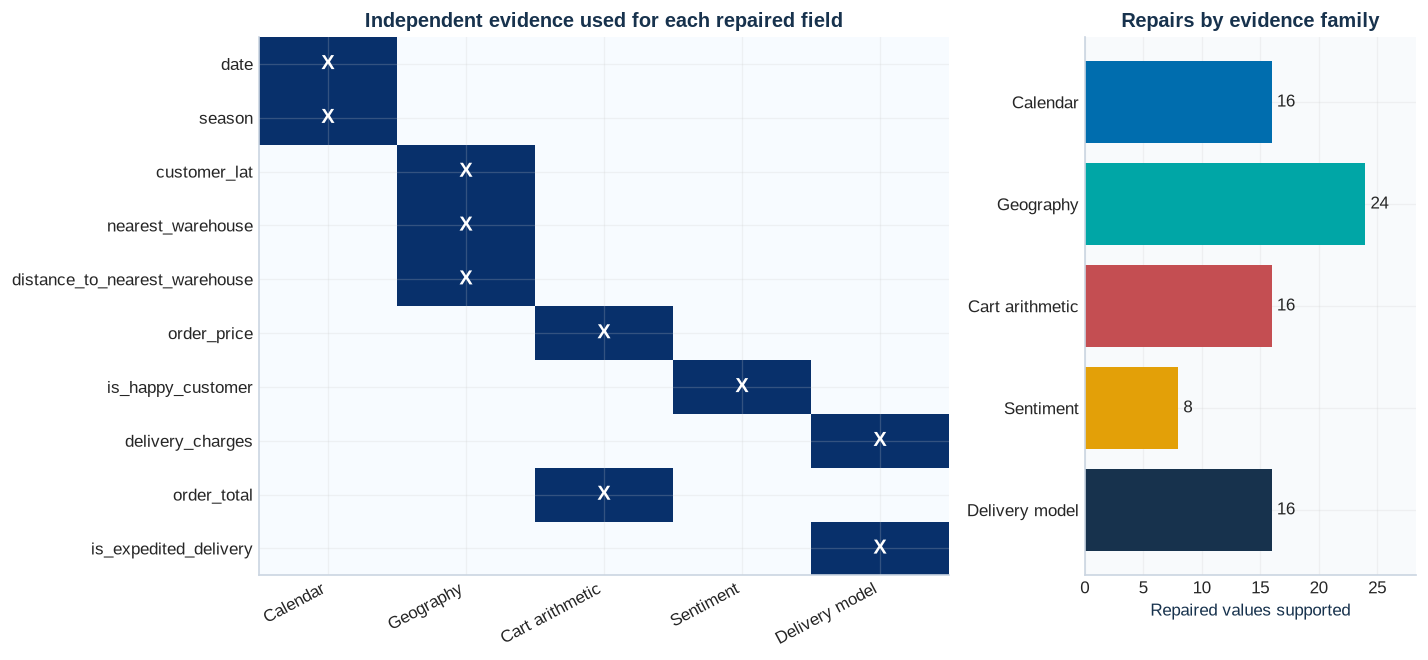

In [40]:
# Purpose: visualise the field-to-evidence mapping and aggregate supported repairs.
family_order = ["Calendar", "Geography", "Cart arithmetic", "Sentiment", "Delivery model"]
evidence_matrix = pd.crosstab(
    pd.Categorical(repair_plot["field_name"], categories=repair_order, ordered=True),
    pd.Categorical(repair_plot["evidence_family"], categories=family_order, ordered=True),
).reindex(index=repair_order, columns=family_order, fill_value=0)
family_totals = (
    repair_plot.groupby("evidence_family")["repaired_values"].sum()
    .reindex(family_order)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.6), gridspec_kw={"width_ratios": [2.5, 1.2]})
axes[0].imshow(evidence_matrix, cmap="Blues", vmin=0, vmax=1, aspect="auto")
axes[0].set_xticks(range(len(family_order)), family_order, rotation=28, ha="right")
axes[0].set_yticks(range(len(repair_order)), repair_order)
for row_index, column_index in zip(*np.where(evidence_matrix.to_numpy() == 1)):
    axes[0].text(column_index, row_index, "X", ha="center", va="center",
                 color="white", fontsize=12, fontweight="bold")
axes[0].set_title("Independent evidence used for each repaired field")

bars = axes[1].barh(family_totals.index, family_totals.values,
                    color=[family_colours[name] for name in family_totals.index])
axes[1].bar_label(bars, padding=3)
axes[1].set(xlabel="Repaired values supported", title="Repairs by evidence family",
            xlim=(0, family_totals.max() * 1.18))
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

We identify 80 affected orders and make exactly one repair in each. There are eight repairs in each of ten field categories. Geography supports 24 repairs; calendar, cart arithmetic and the delivery model each support 16; sentiment supports 8.

## 4.2 Worked examples and monetary isolation

For a valid row,

\[
order\_total = round(order\_price(1-discount/100)+delivery,2).
\]

When this relationship fails, independent cart-price and seasonal-model evidence determine which single monetary field is inconsistent.

In [41]:
# Purpose: show representative dirty repairs and isolate the inconsistent monetary field.
dirty_example_ids = ["CORD000061", "CORD000044", "CORD000060", "CORD000100", "CORD000003"]
dirty_examples = dirty_result.dirty_audit.loc[
    dirty_result.dirty_audit["record_key"].isin(dirty_example_ids),
    ["record_key", "field_name", "original_value", "corrected_value", "method", "evidence"],
]
display(dirty_examples)

monetary_examples = pd.DataFrame(
    {
        "order_id": ["CORD000060", "CORD000100"],
        "published calculation": [
            "5940.94 - 5924.11 = 16.83",
            "round(2223.01 × (1 - 0.20) + 27.20, 2) = 1805.61",
        ],
        "isolated root error": ["delivery_charges", "order_total"],
    }
)
display(monetary_examples)

,record_key,field_name,original_value,corrected_value,method,evidence
3,CORD000044,distance_to_nearest_warehouse,11.5264,7.7764,Recalculate Haversine distance to the nearest warehouse,"D05: 6,371 km radius and four-decimal reconstruction"
7,CORD000061,customer_lat,37.840648,-37.840648,Restore Melbourne latitude sign while retaining precision,D03: supplied warehouses and all reliable customers have southern latitude
56,CORD000060,delivery_charges,24.08,16.83,"Back-calculate charge from validated total, price, and discount",D09: implied-charge model residual=0.0002; observed residual=7.2502
57,CORD000100,order_total,1897.11,1805.61,"Recalculate total from independently validated price, discount, and charge",D08: observed-charge model residual=0.0022; published total formula
72,CORD000003,is_expedited_delivery,False,True,Choose 0/1 state with smaller seasonal-model absolute residual,D10: current residual=9.9992; alternative residual=0.0006


,order_id,published calculation,isolated root error
0,CORD000060,5940.94 - 5924.11 = 16.83,delivery_charges
1,CORD000100,"round(2223.01 × (1 - 0.20) + 27.20, 2) = 1805.61",order_total


For CORD000060, the delivery charge implied by the valid price and total is AUD 16.83. Its model residual is 0.0002, compared with 7.2502 for the original charge, so we use the exact algebraic value rather than a rounded model prediction. For CORD000003, changing the expedited flag from False to True reduces the residual from 9.9992 to 0.0006.

## 4.3 Dirty-output validation

We compare the original and cleaned files by `order_id` and identify every changed field. The checks require at most one change per affected row and exactly one matching audit entry with the submitted corrected value, in addition to the business-rule checks.

In [42]:
# Purpose: display and enforce every dirty-output validation check.
display(dirty_result.validation)
assert dirty_result.validation["passed"].all()

,check,observed_result,passed,interpretation
0,schema_and_column_order,"[order_id, customer_id, date, nearest_warehouse, shopping_cart, order_price, delivery_charges, customer_lat, custome...",True,Output uses the required 16-column schema.
1,row_count,500,True,All dirty-batch rows retained.
2,unique_order_ids,500,True,Order IDs remain unique.
3,preserved_order_id_set,"{'missing': 0, 'unexpected': 0}",True,No order IDs were lost or introduced.
4,required_completeness,0,True,No missing cells exist.
5,canonical_dates,0,True,All dates use YYYY-MM-DD.
6,date_season_relationship,0,True,All seasons match order month.
7,melbourne_coordinates,0,True,Coordinates are consistent with Melbourne.
8,nearest_warehouse_relationship,0,True,Nearest warehouses agree with coordinates.
9,distance_relationship,0.0,True,Distances agree with Haversine calculations.


All 18 dirty-batch checks pass. The cleaned file retains all 500 IDs, has no missing values and satisfies the calendar, location, cart, sentiment, monetary and delivery relationships. All other fields remain equal to their source values.

# 5. Delivery-charge outlier removal

The outlier batch contains potential anomalies in `delivery_charges`. We compare each observed charge with the value expected from its season and predictors, which accounts for valid differences caused by distance and expedited delivery:

\[
residual = observed\_charge - predicted\_charge.
\]

## 5.1 Empirical seasonal thresholds

For each season, we take the larger of the maximum held-out absolute residual and the maximum residual among all reliable observations, then add an AUD 0.01 rounding guard:

\[
T_s = \max(\max |e_{heldout,s}|,\max |e_{reliable,s}|)+0.01.
\]

The threshold is therefore derived from the error we actually observe on clean data, rather than chosen arbitrarily.

In [43]:
# Purpose: run conditional residual-based outlier detection and export retained rows.
outlier_result = clean_outlier_batch(
    outlier_input=OUTLIER_INPUT,
    missing_reference=missing_reference,
    warehouses_input=WAREHOUSES_INPUT,
    outlier_output=OUTLIER_OUTPUT,
    audit_output=AUDIT_OUTPUT,
    prices=missing_result.price_map,
    models=missing_result.seasonal_models,
    analyzer=missing_result.vader_analyzer,
)

display(outlier_result.threshold_diagnostics.round(6))

,season,reliable_observations,heldout_observations,heldout_max_absolute_residual,all_reliable_max_absolute_residual,rounding_guard,residual_threshold
0,Summer,125,25,0.005385,0.005764,0.01,0.015764
1,Autumn,103,21,0.005942,0.005243,0.01,0.015942
2,Winter,116,24,0.005577,0.005448,0.01,0.015577
3,Spring,106,22,0.005915,0.005614,0.01,0.015915


We sort the orders by absolute residual so that the boundary between retained and removed rows is easy to inspect. Colour shows the decision made by the seasonal threshold.

In [44]:
# Purpose: prepare residual diagnostics in ascending error order.
residuals = (
    outlier_result.residual_diagnostics
    .sort_values("absolute_residual")
    .reset_index(drop=True)
)
residual_colours = np.where(
    residuals["remove_as_outlier"], CORAL, MONASH_BLUE
)

The removed residuals are several orders of magnitude larger than the retained residuals, so we use a logarithmic y-axis to show both groups in one figure. Outlier decisions use the residuals in their original AUD scale.

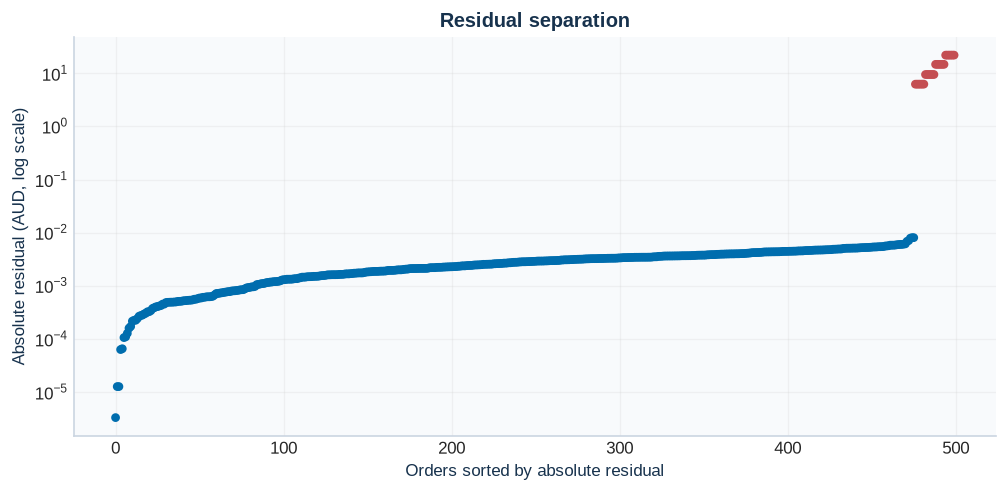

In [45]:
# Purpose: show retained and removed residuals on one readable scale.
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.scatter(
    np.arange(len(residuals)), residuals["absolute_residual"],
    c=residual_colours, s=18,
)
ax.set_yscale("log")
ax.set_xlabel("Orders sorted by absolute residual")
ax.set_ylabel("Absolute residual (AUD, log scale)")
ax.set_title("Residual separation")
plt.tight_layout()
plt.show()

We also compare observed and predicted charges in separate retained and removed panels. Separate limits keep the valid orders readable near the equality line while still showing the much larger errors among removed orders. The five highest retained charges are outlined to show that expensive but model-consistent orders are kept.

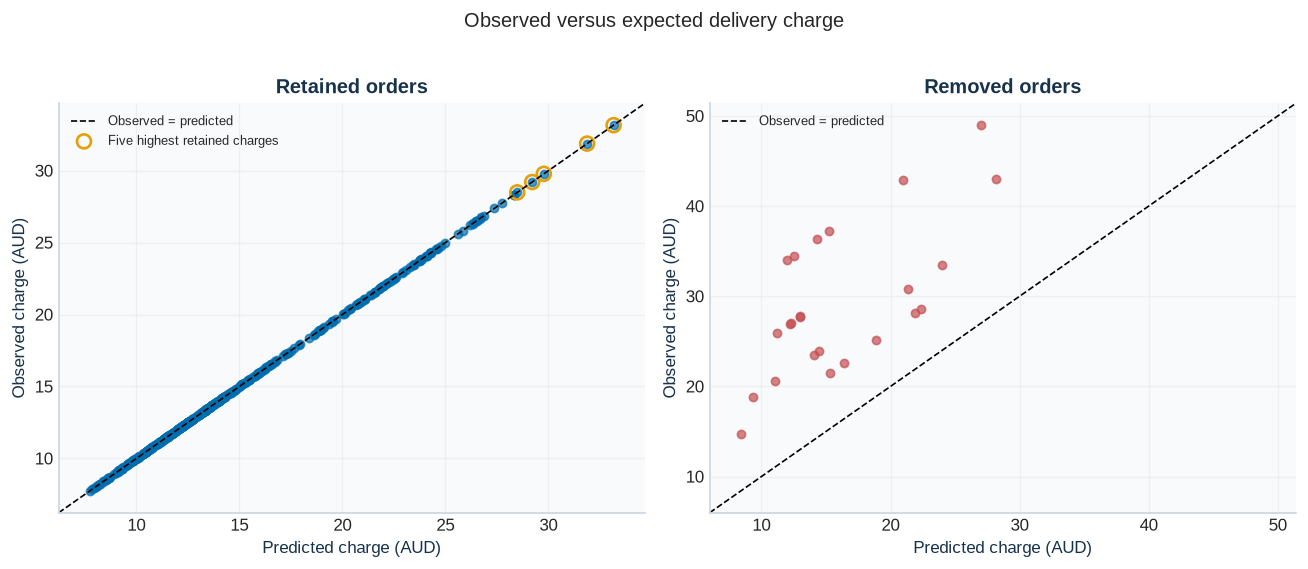

In [46]:
# Purpose: compare retained and removed calibration on readable group-specific scales.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
plot_groups = [
    (residuals.loc[~residuals["remove_as_outlier"]], "Retained orders", MONASH_BLUE),
    (residuals.loc[residuals["remove_as_outlier"]], "Removed orders", CORAL),
]
for axis, (group, title, colour) in zip(axes, plot_groups):
    axis.scatter(group["predicted_delivery_charge"], group["observed_delivery_charge"],
                 color=colour, alpha=0.7, s=24)
    limits = group[["predicted_delivery_charge", "observed_delivery_charge"]].to_numpy()
    low, high = limits.min(), limits.max()
    padding = (high - low) * 0.06
    axis.plot([low - padding, high + padding], [low - padding, high + padding],
              "k--", linewidth=1, label="Observed = predicted")
    axis.set(xlim=(low - padding, high + padding), ylim=(low - padding, high + padding),
             xlabel="Predicted charge (AUD)", ylabel="Observed charge (AUD)", title=title)

highest_valid = plot_groups[0][0].nlargest(5, "observed_delivery_charge")
axes[0].scatter(highest_valid["predicted_delivery_charge"], highest_valid["observed_delivery_charge"],
                facecolors="none", edgecolors=GOLD, linewidths=1.6, s=70,
                label="Five highest retained charges")
for axis in axes:
    axis.legend(frameon=False, fontsize=8)
fig.suptitle("Observed versus expected delivery charge", y=1.02)
plt.tight_layout()
plt.show()

The next summary reconciles the 500 input rows with the retained and removed rows. It also reports the gap between the largest retained residual and the smallest removed residual.

In [47]:
# Purpose: quantify row reconciliation, residual separation and threshold sensitivity.
removed_rows = residuals.loc[residuals["remove_as_outlier"]]
retained_rows = residuals.loc[~residuals["remove_as_outlier"]]

outlier_summary = pd.DataFrame({
    "metric": [
        "input rows", "removed rows", "retained rows",
        "maximum retained absolute residual",
        "minimum removed absolute residual", "separation ratio",
    ],
    "value": [
        len(outlier_raw), len(removed_rows), len(retained_rows),
        retained_rows["absolute_residual"].max(),
        removed_rows["absolute_residual"].min(),
        removed_rows["absolute_residual"].min()
        / retained_rows["absolute_residual"].max(),
    ],
})
display(outlier_summary)

threshold_multipliers = [1, 2, 5, 10, 100]
sensitivity = pd.DataFrame({
    "threshold_multiplier": threshold_multipliers,
    "rows_flagged": [
        int((residuals["absolute_residual"] > multiplier * residuals["residual_threshold"]).sum())
        for multiplier in threshold_multipliers
    ],
})
display(sensitivity)

,metric,value
0,input rows,500.000000
1,removed rows,24.000000
2,retained rows,476.000000
3,maximum retained absolute residual,0.008065
4,minimum removed absolute residual,6.245964
5,separation ratio,774.417115


,threshold_multiplier,rows_flagged
0,1,24
1,2,24
2,5,24
3,10,24
4,100,24


Finally, we inspect examples on both sides of the decision. The removed rows make the anomaly decisions traceable, while the largest retained charges act as counterexamples to a simple high-charge cutoff.

In [48]:
# Purpose: display extreme removals and high-charge retained counterexamples.
display(
    removed_rows
    .sort_values("absolute_residual", ascending=False)
    .head(10)
)
display(
    retained_rows
    .nlargest(8, "observed_delivery_charge")
    [["order_id", "season", "observed_delivery_charge",
      "predicted_delivery_charge", "absolute_residual", "residual_threshold"]]
)

,order_id,season,observed_delivery_charge,predicted_delivery_charge,residual,absolute_residual,residual_threshold,remove_as_outlier
499,CORD001247,Autumn,33.98,11.975584,22.004416,22.004416,0.015942,True
498,CORD001435,Winter,36.33,14.326444,22.003556,22.003556,0.015577,True
497,CORD001099,Summer,37.25,15.249360,22.000640,22.000640,0.015764,True
496,CORD001163,Spring,42.95,20.949916,22.000084,22.000084,0.015915,True
495,CORD001259,Winter,48.98,26.983040,21.996960,21.996960,0.015577,True
494,CORD001063,Autumn,34.52,12.523534,21.996466,21.996466,0.015942,True
493,CORD001258,Autumn,27.76,13.006433,14.753567,14.753567,0.015942,True
492,CORD001478,Spring,27.05,12.296699,14.753301,14.753301,0.015915,True
491,CORD001158,Summer,26.94,12.189373,14.750627,14.750627,0.015764,True
490,CORD001058,Winter,42.96,28.209584,14.750416,14.750416,0.015577,True


,order_id,season,observed_delivery_charge,predicted_delivery_charge,absolute_residual,residual_threshold
224,CORD001381,Winter,33.16,33.162559,0.002559,0.015577
162,CORD001419,Winter,31.88,31.878054,0.001946,0.015577
323,CORD001037,Winter,29.78,29.776418,0.003582,0.015577
197,CORD001482,Winter,29.21,29.212270,0.002270,0.015577
356,CORD001475,Winter,28.49,28.486134,0.003866,0.015577
134,CORD001093,Autumn,28.34,28.338357,0.001643,0.015942
309,CORD001047,Winter,28.34,28.336556,0.003444,0.015577
257,CORD001436,Winter,27.77,27.767053,0.002947,0.015577


We remove the 24 rows whose residuals exceed their seasonal thresholds; their charges are not repaired. The largest retained residual is about AUD 0.0081, while the smallest removed residual is about AUD 6.246, giving a separation ratio above 770. Even when every threshold is multiplied by 100, the same 24 rows are flagged. This shows that the result is stable across a much wider cutoff range. The highest retained charges remain close to their model predictions, confirming that their higher cost is consistent with the delivery relationship.

CORD001017 is one example: its Spring charge is AUD 23.97, the prediction is AUD 14.4692, and the absolute residual is AUD 9.5008 compared with a threshold of about AUD 0.0159. Its audit entry records the original `delivery_charges` value and `ROW_REMOVED`.

## 5.2 Outlier-output validation

We reconcile all 500 input IDs with 476 retained IDs and 24 removed IDs. For retained orders, every cell must match the source. Each removed ID must also have exactly one `outlier_row` entry in the audit log.

In [49]:
# Purpose: display and enforce every outlier-output validation check.
display(outlier_result.validation)
assert outlier_result.validation["passed"].all()

,check,observed_result,passed,interpretation
0,schema_and_column_order,"[order_id, customer_id, date, nearest_warehouse, shopping_cart, order_price, delivery_charges, customer_lat, custome...",True,Output uses the exact required 16-column schema.
1,input_output_row_reconciliation,"{'input_rows': 500, 'removed_rows': 24, 'retained_rows': 476}",True,Input rows equal removed plus retained rows.
2,unique_retained_order_ids,476,True,Retained IDs remain unique.
3,retained_order_id_set,"{'missing': 0, 'unexpected': 0}",True,Output contains exactly the model-rule retained IDs.
4,required_completeness,0,True,No missing values were introduced.
5,preservation_of_retained_values,0,True,Every retained field is equal in meaning to its source value.
6,residual_rule_reconciliation,"{'retained_rule_failures': 0, 'removed_rule_failures': 0}",True,Every removal and retention agrees with its seasonal threshold.
7,residual_separation,"{'maximum_retained_absolute_residual': 0.008065374194757169, 'minimum_removed_absolute_residual': 6.245963811754976,...",True,Removed rows form a clearly separated residual group.
8,shopping_cart_structure,True,True,Retained carts are valid JSON arrays.
9,order_price_relationship,0.0,True,Cart equations reproduce retained prices.


All outlier checks pass. The workflow preserves every value in the 476 retained rows and removes the 24 identified orders.

# 6. Audit trail and final validation

We add an audit entry at the same time as each value is changed or each outlier row is removed. After saving the outputs, we independently compare the inputs and outputs and reconcile those differences with the log. The audit log therefore contains the cleaning changes and row removals.

We use three confidence levels:

- **High:** an exact published relationship gives one value, or an evaluated model gives a clearly separated decision.
- **Medium:** the model-based decision is reasonable, but the residual separation or supporting evidence is weaker.
- **Low:** material uncertainty remains and needs to be reported.

Every Group030 audit decision is classified as high confidence under these definitions. Most corrections follow direct rules, including the month-to-season mapping, nearest-warehouse calculation and order-total formula. For values estimated by the seasonal delivery model, the held-out MAE stays below AUD 0.003 and the largest held-out absolute residual stays below AUD 0.006 across all four seasons. This maximum test error is below one cent, so the model-based estimates agree with the held-out charges to within one cent. Model fitting uses the held-out evaluation described in Section 2.4, while outlier selection uses the empirical seasonal residual thresholds from Section 5.1. The clear gaps between competing residuals provide the evidence for the Boolean repairs and outlier removals.

In [50]:
# Purpose: read back the audit log and verify its required schema and coding.
audit_log = pd.read_csv(AUDIT_OUTPUT, keep_default_na=False)
assert list(audit_log.columns) == [
    "source_file",
    "record_key",
    "field_name",
    "issue_type",
    "original_value",
    "corrected_value",
    "method",
    "evidence",
    "confidence",
]

audit_summary = (
    audit_log.groupby(["source_file", "issue_type", "field_name", "confidence"], as_index=False)
    .size()
    .rename(columns={"size": "audit_rows"})
)
print("Total audit rows:", len(audit_log))
display(audit_summary)

Total audit rows: 184


,source_file,issue_type,field_name,confidence,audit_rows
0,Group030_dirty_data.csv,dirty,customer_lat,high,8
1,Group030_dirty_data.csv,dirty,date,high,8
2,Group030_dirty_data.csv,dirty,delivery_charges,high,8
3,Group030_dirty_data.csv,dirty,distance_to_nearest_warehouse,high,8
4,Group030_dirty_data.csv,dirty,is_expedited_delivery,high,8
5,Group030_dirty_data.csv,dirty,is_happy_customer,high,8
6,Group030_dirty_data.csv,dirty,nearest_warehouse,high,8
7,Group030_dirty_data.csv,dirty,order_price,high,8
8,Group030_dirty_data.csv,dirty,order_total,high,8
9,Group030_dirty_data.csv,dirty,season,high,8


In [51]:
# Purpose: summarise audit volume and preview traceable examples for each issue type.
audit_issue_summary = (
    audit_log["issue_type"]
    .value_counts()
    .reindex(["missing", "dirty", "outlier_row"])
    .rename_axis("issue_type")
    .reset_index(name="audit_rows")
)
audit_issue_summary["share_percent"] = (
    100 * audit_issue_summary["audit_rows"] / len(audit_log)
).round(1)
audit_issue_summary["recorded_action"] = [
    "Missing field replaced",
    "Incorrect field repaired",
    "Order removed; delivery_charges logged",
]

display(audit_issue_summary)
display(audit_log.groupby("issue_type", group_keys=False).head(3))

,issue_type,audit_rows,share_percent,recorded_action
0,missing,80,43.5,Missing field replaced
1,dirty,80,43.5,Incorrect field repaired
2,outlier_row,24,13.0,Order removed; delivery_charges logged


,source_file,record_key,field_name,issue_type,original_value,corrected_value,method,evidence,confidence
0,Group030_missing_data.csv,CORD000594,season,missing,<MISSING>,Summer,Australian season derived from order-date month,M01: published month-to-season mapping,high
1,Group030_missing_data.csv,CORD000610,season,missing,<MISSING>,Summer,Australian season derived from order-date month,M01: published month-to-season mapping,high
2,Group030_missing_data.csv,CORD000652,season,missing,<MISSING>,Autumn,Australian season derived from order-date month,M01: published month-to-season mapping,high
80,Group030_dirty_data.csv,CORD000007,is_happy_customer,dirty,False,True,Apply frozen local VADER compound threshold and sentinel rule,D07: verified lexicon; compound >= 0.05,high
81,Group030_dirty_data.csv,CORD000017,nearest_warehouse,dirty,THOMPSON WH,Thompson,Select minimum Haversine distance to supplied warehouses,"D04: 6,371 km Haversine comparison and canonical warehouse name",high
82,Group030_dirty_data.csv,CORD000035,nearest_warehouse,dirty,THOMPSON WH,Thompson,Select minimum Haversine distance to supplied warehouses,"D04: 6,371 km Haversine comparison and canonical warehouse name",high
160,Group030_outlier_data.csv,CORD001017,delivery_charges,outlier_row,23.97,ROW_REMOVED,Remove row when seasonal-model absolute residual exceeds empirical threshold,"O01: Spring observed=23.97, predicted=14.4692, abs residual=9.5008, threshold=0.0159",high
161,Group030_outlier_data.csv,CORD001040,delivery_charges,outlier_row,28.12,ROW_REMOVED,Remove row when seasonal-model absolute residual exceeds empirical threshold,"O01: Summer observed=28.12, predicted=21.8660, abs residual=6.2540, threshold=0.0158",high
162,Group030_outlier_data.csv,CORD001057,delivery_charges,outlier_row,20.55,ROW_REMOVED,Remove row when seasonal-model absolute residual exceeds empirical threshold,"O01: Autumn observed=20.55, predicted=11.0495, abs residual=9.5005, threshold=0.0159",high


The compact summary accounts for all 184 audit rows: 80 missing-value replacements, 80 dirty-field repairs and 24 outlier removals. The examples below it show how each issue type is recorded. We write `<MISSING>` for an empty source value and `ROW_REMOVED` for an order removed from the outlier output.

## 6.1 Consolidated validation evidence

We combine the checks returned by the three cleaning workflows in one table. The earlier sections provide the observed values, examples and interpretations behind this summary.

In [52]:
# Purpose: combine all executable checks into one cross-batch validation summary.
all_validation = pd.concat(
    [
        missing_result.validation.assign(batch="missing"),
        dirty_result.validation.assign(batch="dirty"),
        outlier_result.validation.assign(batch="outlier"),
    ],
    ignore_index=True,
)
validation_summary = (
    all_validation.groupby("batch")["passed"]
    .agg(checks="size", passed="sum")
    .reset_index()
)
validation_summary["failed"] = validation_summary["checks"] - validation_summary["passed"]
display(validation_summary)
assert all_validation["passed"].all()

,batch,checks,passed,failed
0,dirty,18,18,0
1,missing,15,15,0
2,outlier,17,17,0


In [53]:
# Purpose: read back final files and report row counts, sizes and SHA-256 fingerprints.
output_paths = {
    "dirty_clean": DIRTY_OUTPUT,
    "missing_clean": MISSING_OUTPUT,
    "outlier_clean": OUTLIER_OUTPUT,
    "audit_log": AUDIT_OUTPUT,
}
output_summary = []
for label, path in output_paths.items():
    frame = pd.read_csv(path, keep_default_na=False)
    output_summary.append(
        {
            "output": label,
            "filename": path.name,
            "rows": len(frame),
            "columns": frame.shape[1],
            "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
        }
    )
display(pd.DataFrame(output_summary))

,output,filename,rows,columns,sha256
0,dirty_clean,Group030_dirty_clean.csv,500,16,28a62e53917f0b2230d4c820f22819d3967ed606c8fcee1214fa870e9337c0d0
1,missing_clean,Group030_missing_clean.csv,500,16,e0ce24754c1de8cb5b6851c694d9d858ed42b91104cfa5c169cdb3b3671c899b
2,outlier_clean,Group030_outlier_clean.csv,476,16,b68b7709d301538040022f53decc77a61a558f6d3359f8561bae1ae0c938bd3c
3,audit_log,audit_log.csv,184,9,f6b1ec97af9eecf72a9f75be6d14ee3df03b5c50d9260dc7db9b5355471871bd


All four saved files can be read back successfully. The dirty and missing outputs each contain 500 orders, and the outlier output contains 476. The hashes identify the exact files produced by this run, while the relationship, preservation and reconciliation checks test their contents.

# 7. Customer profiling and transformation

For Task 3, we create a separate analysis copy from the three cleaned CSVs. It contains the 1,476 retained orders, so the resulting profiles describe the available A2 sample for each customer.

In [54]:
# Purpose: combine the three cleaned outputs while preserving source-batch identity.
cleaned_paths = {
    "dirty": DIRTY_OUTPUT,
    "missing": MISSING_OUTPUT,
    "outlier": OUTLIER_OUTPUT,
}
cleaned_frames = []
for source_batch, path in cleaned_paths.items():
    frame = pd.read_csv(path, **read_options)
    frame["source_batch"] = source_batch
    cleaned_frames.append(frame)

profile_orders = pd.concat(cleaned_frames, ignore_index=True)
profile_input_summary = pd.DataFrame(
    {
        "source_batch": list(cleaned_paths),
        "retained_rows": [len(frame) for frame in cleaned_frames],
    }
)
display(profile_input_summary)
print("Combined distinct orders:", profile_orders["order_id"].nunique())
print("Customers represented:", profile_orders["customer_id"].nunique())

,source_batch,retained_rows
0,dirty,500
1,missing,500
2,outlier,476


Combined distinct orders: 1476
Customers represented: 471


The combined analysis contains 1,476 distinct orders from 471 customers. We keep the source-batch label for traceability and then aggregate the orders to one row per `customer_id`.

## 7.1 Customer-level attributes

We calculate all four candidate attributes and select three for the distance comparison:

- `order_count`, representing activity frequency;
- `mean_order_value`, representing typical paid value including delivery;
- `mean_delivery_distance`, representing delivery geography.

We also calculate `total_paid`, then exclude it from the selected features because `total_paid = order_count × mean_order_value`. Including all three spending-related measures would give the same purchasing information extra weight in Euclidean distance.

In [55]:
# Purpose: aggregate retained orders to one row per customer and select three attributes.
customer_profiles = (
    profile_orders.groupby("customer_id", as_index=False)
    .agg(
        order_count=("order_id", "nunique"),
        total_paid=("order_total", "sum"),
        mean_order_value=("order_total", "mean"),
        mean_delivery_distance=("distance_to_nearest_warehouse", "mean"),
    )
)
selected_attributes = ["order_count", "mean_order_value", "mean_delivery_distance"]
baseline_profiles = customer_profiles[["customer_id", *selected_attributes]].copy()

display(customer_profiles.head())
display(baseline_profiles[selected_attributes].describe().T)

,customer_id,order_count,total_paid,mean_order_value,mean_delivery_distance
0,CUS00001,3,12257.60,4085.866667,4.1886
1,CUS00002,2,8586.37,4293.185000,3.5348
2,CUS00003,1,5210.66,5210.660000,7.7936
3,CUS00005,5,28407.04,5681.408000,8.5114
4,CUS00006,3,13394.31,4464.770000,5.1893


,count,mean,std,min,25%,50%,75%,max
order_count,471.0,3.133758,1.590245,1.0000,2.00000,3.000000,4.00000,10.0000
mean_order_value,471.0,4240.260855,1570.159254,815.5800,3218.19125,4134.523333,5052.62800,11497.8000
mean_delivery_distance,471.0,5.350370,2.177862,0.4852,3.85005,5.525300,7.05705,10.1316


## 7.2 Original scales, distributions and relationships

We first examine the three selected attributes in their original units. Their ranges are very different: order value is measured in thousands of dollars, while order count and delivery distance are mostly single-digit values. Without scaling, the monetary variable would dominate a distance calculation.

In [56]:
# Purpose: summarise original customer-profile scales and skewness.
distribution_summary = pd.DataFrame(
    {
        "minimum": baseline_profiles[selected_attributes].min(),
        "median": baseline_profiles[selected_attributes].median(),
        "mean": baseline_profiles[selected_attributes].mean(),
        "maximum": baseline_profiles[selected_attributes].max(),
        "standard_deviation": baseline_profiles[selected_attributes].std(ddof=1),
        "skewness": baseline_profiles[selected_attributes].skew(),
        "zeros": (baseline_profiles[selected_attributes] == 0).sum(),
    }
)
display(distribution_summary.round(4))

,minimum,median,mean,maximum,standard_deviation,skewness,zeros
order_count,1.0000,3.0000,3.1338,10.0000,1.5902,0.8793,0
mean_order_value,815.5800,4134.5233,4240.2609,11497.8000,1570.1593,0.9282,0
mean_delivery_distance,0.4852,5.5253,5.3504,10.1316,2.1779,-0.2357,0


We use a frequency chart for the discrete order counts and histograms for the two continuous attributes. Median lines and horizontal boxplots show centre, spread and extreme observations on the original scales.

In [57]:
# Purpose: define readable labels and colours for the selected attributes.
profile_colours = [MONASH_BLUE, CORAL, TEAL]
profile_labels = [
    "Order count",
    "Mean order value (AUD)",
    "Mean delivery distance (km)",
]

Order count is plotted with one bar for each observed integer. For order value and delivery distance, equal-width histograms show the shape of the continuous distributions, and the dashed line marks the median.

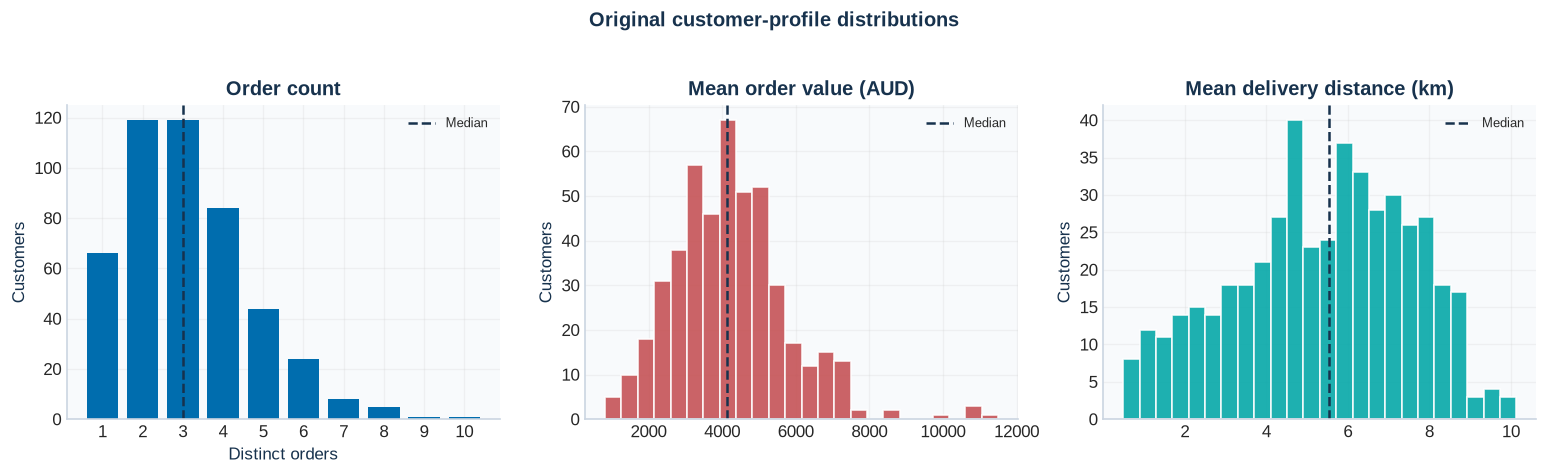

In [58]:
# Purpose: plot discrete and continuous customer attributes appropriately.
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
count_values = baseline_profiles["order_count"].value_counts().sort_index()
axes[0].bar(count_values.index, count_values.values, color=profile_colours[0], width=0.78)
axes[0].set_xticks(count_values.index)
axes[0].axvline(baseline_profiles["order_count"].median(), color=NAVY,
                linestyle="--", linewidth=1.5, label="Median")
axes[0].set(title=profile_labels[0], ylabel="Customers", xlabel="Distinct orders")
axes[0].legend(fontsize=8)

for axis, attribute, label, colour in zip(
    axes[1:], selected_attributes[1:], profile_labels[1:], profile_colours[1:]
):
    values = baseline_profiles[attribute]
    axis.hist(values, bins=24, color=colour, alpha=0.88, edgecolor="white")
    axis.axvline(values.median(), color=NAVY, linestyle="--",
                 linewidth=1.5, label="Median")
    axis.set(title=label, ylabel="Customers")
    axis.legend(fontsize=8)
fig.suptitle("Original customer-profile distributions", color=NAVY, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

The horizontal boxplots give a second view of the same untransformed variables, focusing on the median, interquartile range and tails.

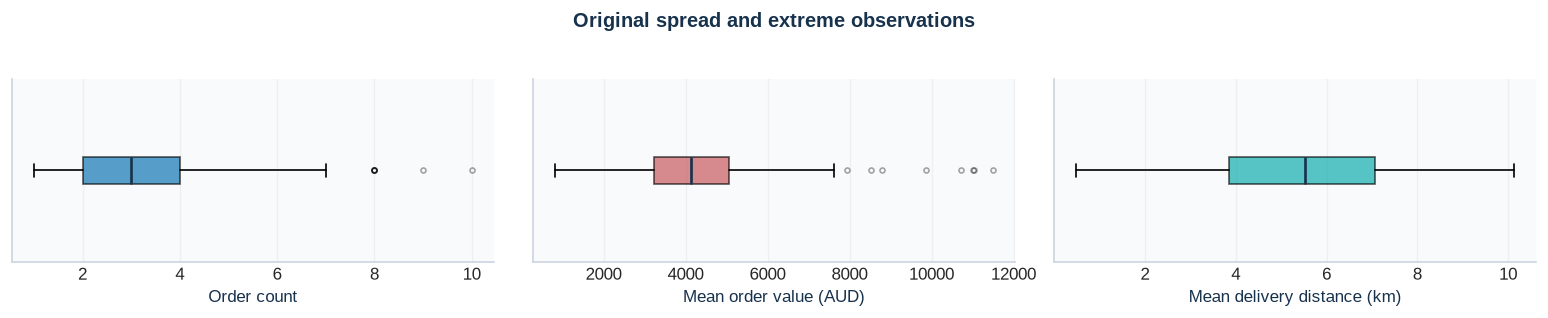

In [59]:
# Purpose: show robust spread summaries for the original features.
fig, axes = plt.subplots(1, 3, figsize=(13, 2.5))
for axis, attribute, label, colour in zip(
    axes, selected_attributes, profile_labels, profile_colours
):
    axis.boxplot(
        baseline_profiles[attribute], orientation="horizontal", patch_artist=True,
        boxprops={"facecolor": colour, "alpha": 0.65},
        medianprops={"color": NAVY, "linewidth": 1.6},
        flierprops={"marker": "o", "markersize": 3, "alpha": 0.35},
    )
    axis.set_xlabel(label)
    axis.set_yticks([])
fig.suptitle("Original spread and extreme observations", color=NAVY, fontweight="bold", y=1.04)
plt.tight_layout()
plt.show()

We calculate Pearson correlations as a simple check for linear redundancy. Small absolute correlations indicate that the selected attributes contain limited overlapping linear information.

In [60]:
# Purpose: quantify linear association among the selected profile attributes.
correlations = baseline_profiles[selected_attributes].corr()
display(correlations.round(3))

,order_count,mean_order_value,mean_delivery_distance
order_count,1.000,0.092,-0.009
mean_order_value,0.092,1.000,0.026
mean_delivery_distance,-0.009,0.026,1.000


The scatter plots let us check relationships that one correlation coefficient might hide, including the discrete bands in order count and any unusual observations. Each title also reports the corresponding Pearson correlation.

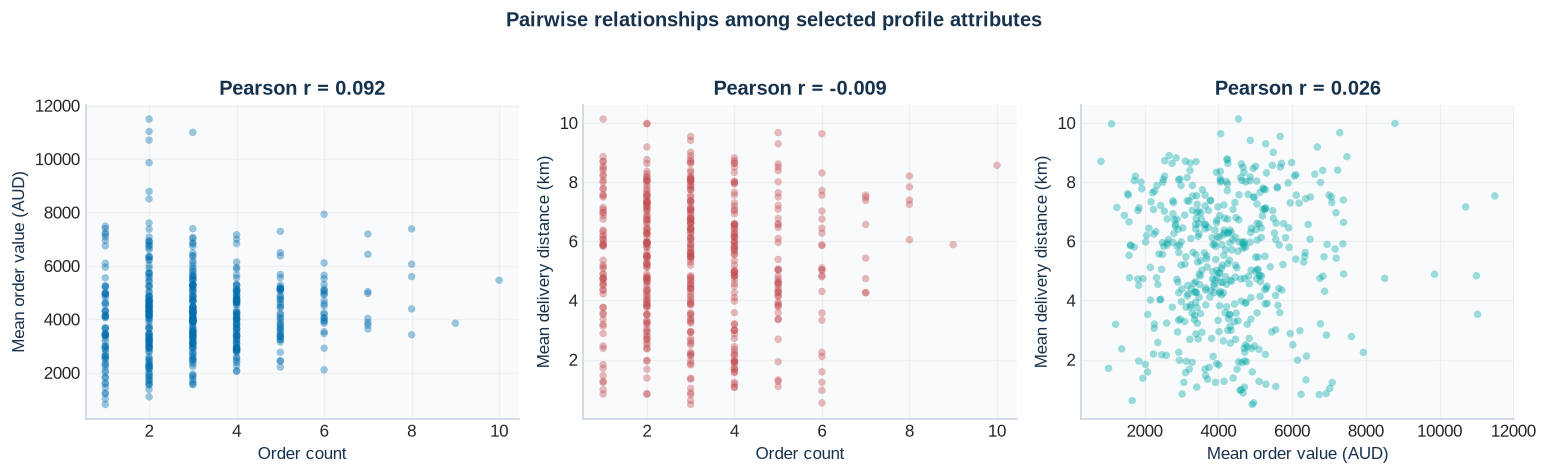

In [61]:
# Purpose: visualise every pair of selected attributes.
attribute_pairs = [
    ("order_count", "mean_order_value"),
    ("order_count", "mean_delivery_distance"),
    ("mean_order_value", "mean_delivery_distance"),
]
label_by_attribute = dict(zip(selected_attributes, profile_labels))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

for axis, (x_name, y_name), colour in zip(axes, attribute_pairs, profile_colours):
    x_values = baseline_profiles[x_name]
    y_values = baseline_profiles[y_name]
    correlation = x_values.corr(y_values)
    axis.scatter(
        x_values, y_values, s=20, alpha=0.38,
        color=colour, edgecolors="none", rasterized=True,
    )
    axis.set_xlabel(label_by_attribute[x_name])
    axis.set_ylabel(label_by_attribute[y_name])
    axis.set_title(f"Pearson r = {correlation:.3f}")

fig.suptitle("Pairwise relationships among selected profile attributes", color=NAVY, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

`order_count` and `mean_order_value` are moderately right-skewed, while `mean_delivery_distance` is only mildly left-skewed. The pairwise Pearson correlations are close to zero (|r| ≤ 0.092), indicating little linear redundancy among the selected attributes. This supports our decision to avoid the stronger redundancy that would come from selecting order count, total paid and mean order value together.

## 7.3 Standardisation and min-max scaling

We compare the two required scaling methods:

\[
z=(x-\mu)/\sigma, \qquad x'=(x-\min x)/(\max x-\min x).
\]

Z-score standardisation expresses values in standard-deviation units. Min-max scaling maps the observed range to `[0,1]`, although observations near the centre can be compressed when an extreme value sets one endpoint.

We apply `StandardScaler` and `MinMaxScaler` to the same three attributes. The first centres each attribute at zero with population variance one; the second maps its observed minimum and maximum to 0 and 1.

In [62]:
# Purpose: create z-score and min-max versions of the same three baseline features.
z_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

z_scaled = pd.DataFrame(
    z_scaler.fit_transform(baseline_profiles[selected_attributes]),
    columns=[f"{column}_z" for column in selected_attributes],
    index=baseline_profiles.index,
)
minmax_scaled = pd.DataFrame(
    minmax_scaler.fit_transform(baseline_profiles[selected_attributes]),
    columns=[f"{column}_minmax" for column in selected_attributes],
    index=baseline_profiles.index,
)

We calculate summary statistics after scaling to confirm the resulting means, standard deviations and ranges.

In [63]:
# Purpose: verify centring, variance and endpoints after scaling.
scaling_comparison = pd.DataFrame({
    "original_range": (
        baseline_profiles[selected_attributes].max()
        - baseline_profiles[selected_attributes].min()
    ),
    "z_mean": z_scaled.mean().to_numpy(),
    "z_std_population": z_scaled.std(ddof=0).to_numpy(),
    "minmax_min": minmax_scaled.min().to_numpy(),
    "minmax_max": minmax_scaled.max().to_numpy(),
}, index=selected_attributes)

display(scaling_comparison.round(6))

,original_range,z_mean,z_std_population,minmax_min,minmax_max
order_count,9.0000,-0.0,1.0,0.0,1.0
mean_order_value,10682.2200,0.0,1.0,0.0,1.0
mean_delivery_distance,9.6464,-0.0,1.0,0.0,1.0


For unweighted Euclidean distance, a variable with larger variance tends to contribute more to the squared distance. We therefore calculate each attribute's share of total variance under the original, z-score and min-max representations.

In [64]:
# Purpose: compute each feature's share of total variance by representation.
variance_by_representation = pd.DataFrame({
    "original": baseline_profiles[selected_attributes].var(ddof=0),
    "z_score": z_scaled.set_axis(selected_attributes, axis=1).var(ddof=0),
    "min_max": minmax_scaled.set_axis(selected_attributes, axis=1).var(ddof=0),
})

distance_contribution = variance_by_representation.div(
    variance_by_representation.sum(axis=0), axis=1
) * 100

display(distance_contribution.round(4))

,original,z_score,min_max
order_count,0.0001,33.3333,30.0783
mean_order_value,99.9997,33.3333,20.8149
mean_delivery_distance,0.0002,33.3333,49.1067


The stacked bars show these variance shares side by side. This makes it easy to see whether one measurement scale dominates a representation.

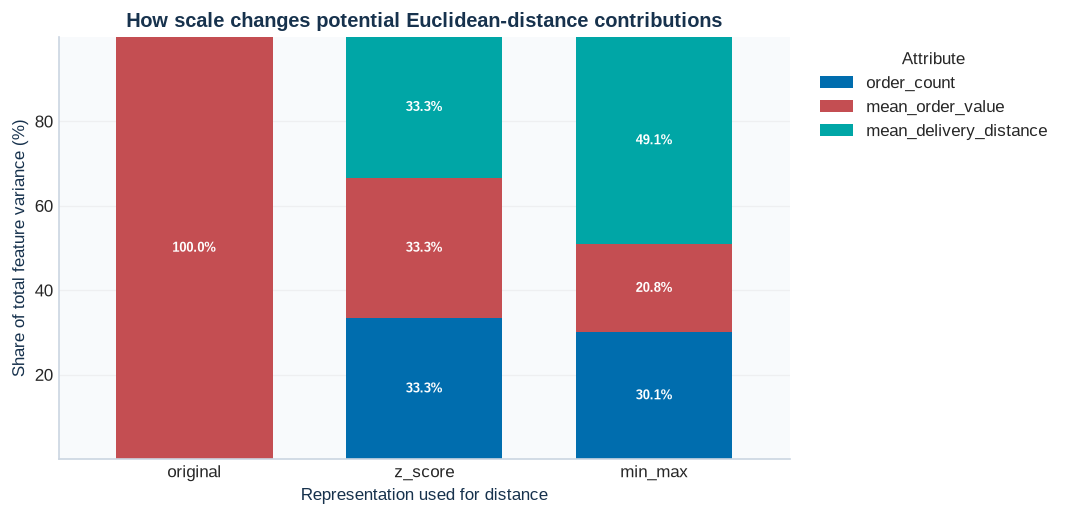

In [65]:
# Purpose: visualise potential feature contributions to Euclidean distance.
ax = distance_contribution.T.plot(
    kind="bar", stacked=True, figsize=(9, 4.4),
    color=profile_colours, width=0.68,
)
for container in ax.containers:
    labels = [f"{value:.1f}%" if value >= 6 else "" for value in container.datavalues]
    ax.bar_label(
        container, labels=labels, label_type="center",
        color="white", fontsize=8, fontweight="bold",
    )
ax.set_ylabel("Share of total feature variance (%)")
ax.set_xlabel("Representation used for distance")
ax.set_title("How scale changes potential Euclidean-distance contributions")
ax.legend(title="Attribute", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

On the original scale, `mean_order_value` contributes about 99.9997% of total feature variance simply because it is measured in thousands of dollars. Order count and distance then have almost no numerical influence. Z-score standardisation gives each attribute one-third of the variance by construction. Min-max scaling removes the units but does not equalise variance; its approximate shares are 30.08%, 20.81% and 49.11%. Both methods address the unit difference, but neither removes skewness. Min-max scaling depends on the observed endpoints, while z-scores can still be extreme and implicitly assign equal variance weight to the three attributes.

## 7.4 Nonlinear transformation comparison

All three selected attributes are non-negative, so square-root and `log1p` transformations are mathematically valid. We compare both with the original values, considering distribution shape as well as the meaning of each attribute. When a nonlinear transformation is combined with scaling, we apply the transformation first and fit the scaler afterwards.

For each attribute, we calculate skewness and range summaries for the original, square-root and `log1p` versions. This shows how much each transformation changes the distribution.

In [66]:
# Purpose: define candidate transformations and summarise their observed effects.
transformations = {
    "original": lambda values: values,
    "square_root": np.sqrt,
    "log1p": np.log1p,
}

nonlinear_records = []
for attribute in selected_attributes:
    for method, transform in transformations.items():
        transformed = transform(baseline_profiles[attribute])
        nonlinear_records.append({
            "attribute": attribute,
            "method": method,
            "skewness": transformed.skew(),
            "minimum": transformed.min(),
            "median": transformed.median(),
            "maximum": transformed.max(),
        })

nonlinear_summary = pd.DataFrame(nonlinear_records)
display(nonlinear_summary.round(4))

,attribute,method,skewness,minimum,median,maximum
0,order_count,original,0.8793,1.0000,3.0000,10.0000
1,order_count,square_root,0.2240,1.0000,1.7321,3.1623
2,order_count,log1p,-0.0573,0.6931,1.3863,2.3979
3,mean_order_value,original,0.9282,815.5800,4134.5233,11497.8000
4,mean_order_value,square_root,0.1560,28.5584,64.3003,107.2278
5,mean_order_value,log1p,-0.5920,6.7051,8.3274,9.3500
6,mean_delivery_distance,original,-0.2357,0.4852,5.5253,10.1316
7,mean_delivery_distance,square_root,-0.7402,0.6966,2.3506,3.1830
8,mean_delivery_distance,log1p,-1.0493,0.3955,1.8757,2.4098


The grid of plots provides the visual comparison. Each row is one attribute, and each column is one transformation. Median lines and skewness labels help us see when a transformation reduces asymmetry or compresses the values too strongly.

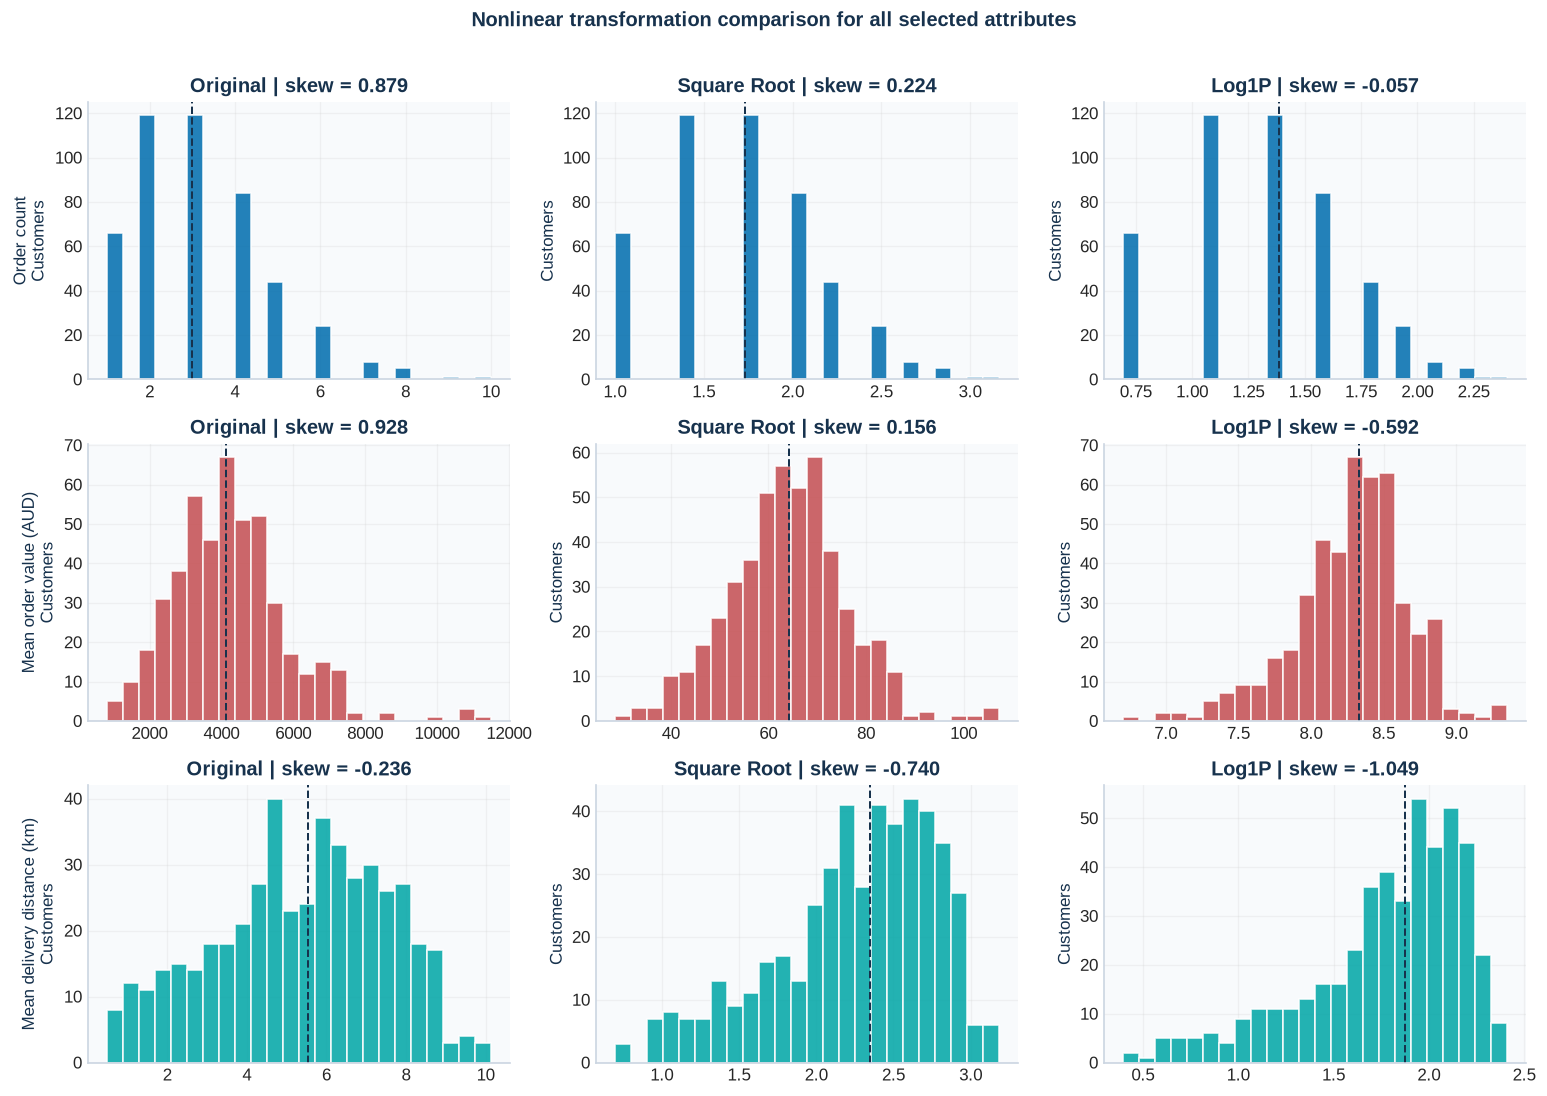

In [67]:
# Purpose: compare all three transformation choices for every selected attribute.
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for row_index, (attribute, label, colour) in enumerate(
    zip(selected_attributes, profile_labels, profile_colours)
):
    for column_index, (method, transform) in enumerate(transformations.items()):
        transformed = transform(baseline_profiles[attribute])
        axis = axes[row_index, column_index]
        axis.hist(transformed, bins=24, color=colour, alpha=0.86, edgecolor="white")
        axis.axvline(transformed.median(), color=NAVY, linestyle="--", linewidth=1.2)
        axis.set_title(
            f"{method.replace('_', ' ').title()} | skew = {transformed.skew():.3f}"
        )
        axis.set_ylabel(f"{label}\nCustomers" if column_index == 0 else "Customers")

fig.suptitle("Nonlinear transformation comparison for all selected attributes", color=NAVY, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

The results support a different choice for each attribute. For `order_count`, square root lowers skewness from 0.8793 to 0.2240 and `log1p` lowers it to -0.0573, but both compress an already short, discrete 1–10 scale and make the meaning of one extra order less direct. For `mean_order_value`, square root lowers skewness from 0.9282 to 0.1560 while keeping more separation among high-value customers than `log1p`, which reverses the skew to -0.5920. We therefore prefer square root for this attribute. For `mean_delivery_distance`, the original skewness is only -0.2357, and both transformations make it more negative, so we keep the original form. These choices reduce the influence of a few high-value customers while keeping each attribute interpretable; they do not by themselves show that meaningful customer groups exist.

## 7.5 Recommended analytical treatment

We build the recommended profile as a separate in-memory analysis table. Customer IDs are kept as identifiers, and none of the transformed values are written back to the cleaned CSVs or the audit log.

We apply a square-root transformation to `mean_order_value` and keep the other two attributes in their original form. We then fit one z-score scaler to this three-column profile matrix.

In [68]:
# Purpose: apply the selected nonlinear treatment before standardisation.
recommended_base = pd.DataFrame({
    "order_count": baseline_profiles["order_count"],
    "mean_order_value": np.sqrt(baseline_profiles["mean_order_value"]),
    "mean_delivery_distance": baseline_profiles["mean_delivery_distance"],
})

# Purpose: put all recommended features on comparable variance scales.
recommended_scaler = StandardScaler()
recommended_scaled = pd.DataFrame(
    recommended_scaler.fit_transform(recommended_base),
    columns=[f"{column}_recommended" for column in recommended_base.columns],
)
recommended_profiles = pd.concat(
    [baseline_profiles[["customer_id"]], recommended_scaled], axis=1
)

We summarise one decision for each attribute, linking the methods we compared with the observed effect, our selected treatment and an important limitation.

In [69]:
# Purpose: assemble the required recommendation table.
recommendations = pd.DataFrame([
    {
        "attribute": "order_count",
        "methods_compared": "original, square root, log1p, z-score, min-max",
        "observed_effect": "Skew 0.8793; transforms reduce skew but compress the discrete 1–10 count scale",
        "recommended_treatment": "no nonlinear transformation; z-score standardisation",
        "justification_or_limitation": "Preserves count interpretation before scaling; z-score equal weighting is sample-specific",
    },
    {
        "attribute": "mean_order_value",
        "methods_compared": "original, square root, log1p, z-score, min-max",
        "observed_effect": "Square root reduces skew from about 0.93 to 0.16; log1p over-compresses the upper tail",
        "recommended_treatment": "square root first; then z-score standardisation",
        "justification_or_limitation": "Moderates monetary influence; transformed units are less direct and z-scores do not cap extremes",
    },
    {
        "attribute": "mean_delivery_distance",
        "methods_compared": "original, square root, log1p, z-score, min-max",
        "observed_effect": "Skew −0.2357; square root and log1p worsen it to −0.7402 and −1.0493",
        "recommended_treatment": "no nonlinear transformation; z-score standardisation",
        "justification_or_limitation": "Retains kilometre ordering; straight-line distance is not travel time and equal weight is a choice",
    },
])

The final table presents these recommendations together. We also show the first five rows of the transformed profile so that the alignment between customer IDs and the three recommended features can be checked.

In [70]:
# Purpose: display the recommendation evidence and a sample of the analysis matrix.
display(
    recommendations.style
    .hide(axis="index")
    .set_properties(**{
        "text-align": "left", "white-space": "normal", "max-width": "280px"
    })
    .set_table_styles([
        {"selector": "th", "props": [
            ("background-color", NAVY), ("color", "white"), ("text-align", "left")
        ]},
        {"selector": "tbody tr:nth-child(even)", "props": [
            ("background-color", "#F4F8FB")
        ]},
    ])
)
display(recommended_profiles.head().style.format(precision=3).hide(axis="index"))

attribute,methods_compared,observed_effect,recommended_treatment,justification_or_limitation
order_count,"original, square root, log1p, z-score, min-max",Skew 0.8793; transforms reduce skew but compress the discrete 1–10 count scale,no nonlinear transformation; z-score standardisation,Preserves count interpretation before scaling; z-score equal weighting is sample-specific
mean_order_value,"original, square root, log1p, z-score, min-max",Square root reduces skew from about 0.93 to 0.16; log1p over-compresses the upper tail,square root first; then z-score standardisation,Moderates monetary influence; transformed units are less direct and z-scores do not cap extremes
mean_delivery_distance,"original, square root, log1p, z-score, min-max",Skew −0.2357; square root and log1p worsen it to −0.7402 and −1.0493,no nonlinear transformation; z-score standardisation,Retains kilometre ordering; straight-line distance is not travel time and equal weight is a choice


customer_id,order_count_recommended,mean_order_value_recommended,mean_delivery_distance_recommended
CUS00001,-0.084,-0.008,-0.534
CUS00002,-0.714,0.126,-0.835
CUS00003,-1.343,0.684,1.123
CUS00005,1.175,0.951,1.453
CUS00006,-0.084,0.235,-0.074


Based on these comparisons, we recommend z-score standardisation for all three selected features. We first apply a square-root transformation to `mean_order_value`, while keeping `order_count` and `mean_delivery_distance` in their original forms.

This gives the three attributes comparable numerical influence while keeping their distributions and meanings useful. Equal variance represents an analytical weighting choice, and z-score scaling leaves the observed distribution shapes and extreme values visible. The resulting profiles are intended for exploratory distance comparisons within the retained A2 orders.

# References

- FIT5196 Assessment 2 specification, Semester 2 2026.  
- FIT5196 Assessment 2 marking rubric, Semester 2 2026, version 1.5.  
- scikit-learn documentation: `LinearRegression`, `StandardScaler` and `MinMaxScaler`.  
- NLTK VADER sentiment analyser, using the supplied frozen local lexicon.  
- Monash University Brand Book, “Our logo”: https://www.monash.edu/brandbook/brand-elements/our-logo  
- Monash University logo asset reused from the Group030 A1 submission.

AI use and independent verification are documented separately in the required declaration and conversation index.